# 1. Project Title and Group Members

# Image Forgery Detection Using Classical Image Processing Techniques
### Phase 3 — Final Pipeline, Experiments and Evaluation

| | |
|---|---|
| **Group** | **J** |
| **Members** | Smit Patel (2479966), Ananay Gupta (2618966) |
| **Course** | EDS 6364 — Digital Image Processing |

### Contributions of each member
The work was **split equally** between the two members. Each member was responsible for four of the eight pipeline stages (Stages 0–7, see Section 4), and the experiments, evaluation and write-up were done jointly, in line with Section 7 (*Team Responsibilities*) of our Phase 1 proposal.

| Member | Pipeline stages (own responsibility) | Shared work (both members) |
|---|---|---|
| **Smit Patel** (50 %) | **Stage 0** dataset preparation and preprocessing (protocol R) · **Stage 1** point processing (ELA, JPEG ghosts) · **Stage 2** histogram processing · **Stage 3** spatial filtering | Parameter experiments, evaluation, before-and-after visualisations, this notebook and the final report |
| **Ananay Gupta** (50 %) | **Stage 4** frequency domain (DCT double quantisation, DCT-block copy-move) · **Stage 5** edge and corner detection (Canny, SIFT copy-move) · **Stage 6** feature fusion and classifier training · **Stage 7** localisation | Parameter experiments, evaluation, before-and-after visualisations, this notebook and the final report |

**Contents:** 1 Title, group and contributions · 2 Overview and objective · 3 Dataset and sample images · 4 Final pipeline (4.1 which version is final) · 5 Python implementation · 6 Experiments and parameter comparison · 7 Final results and evaluation · 8 Challenges, improvements and conclusion

# 2. Project Overview and Objective

**The problem.** Photographs are easy to edit, and some edits are made to deceive. In a **copy-move** forgery a region is duplicated inside the same image, to hide an object or to repeat one. In a **splicing** forgery a region from another photograph is pasted in. Such forgeries matter for journalism, insurance-fraud review and scientific-image integrity.

**The objective.** Decide whether an image has been tampered with and show **where**, using classical, interpretable image-processing evidence instead of a black-box model. The pipeline draws on all five technique categories of the course: point processing, histogram processing, spatial filtering, frequency-domain filtering, and edge and corner detection.

**The expected outcome.** For every input image the pipeline produces:
1. a **verdict** with a probability: *tampered*, *authentic*, or *uncertain* (it abstains when the evidence is weak);
2. a **map and mask** of the suspected region;
3. **evidence maps** from each technique that explain the decision.

It is evaluated against the dataset's ground-truth masks.

**One finding changed how we evaluate.** The dataset we use, CASIA v2.0, leaks its labels through file format: file metadata alone separates the classes with 0.990 balanced accuracy. Every image is therefore first normalised (Stage 0), and every result is compared with what such shortcuts achieve alone. Section 3 shows the evidence.

In [1]:
# ---- environment: the notebook finds the project folder itself, no paths need editing ----------------------
import sys, json, warnings
from pathlib import Path
from types import SimpleNamespace

import os
NB_DIR = Path.cwd()                                    # the folder this notebook is in
# the project (code, models, saved results): next to the notebook, or in ../Project when the submission zip is used
HERE = next((p for p in (NB_DIR, NB_DIR.parent / "Project") if (p / "src" / "forgery").exists()), None)
assert HERE is not None, "Keep the Submission and Project folders of GroupJ_Phase3.zip side by side (see README.txt)."
# the supporting images: Submission/supporting_images in the zip, sample_images/ next to the code otherwise
IMAGES = next(p for p in (NB_DIR / "supporting_images", HERE / "sample_images") if p.exists())
os.chdir(HERE)                                         # every other path below is relative to the project folder
sys.path.insert(0, str(HERE / "src"))

import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

from forgery.config import load_config
from forgery.io import load_rgb, load_mask, protocol_mask, jpeg_roundtrip, apply_protocol, ijg_table
from forgery.features import build_modules
from forgery.pipeline import module_params, verdict_from_probability
from forgery.localize.fusion import scores as region_scores
from forgery import explain as E

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 9})
np.random.seed(42)

cfg = load_config()                                    # tuned parameters (config.yaml)
TUNED = module_params(cfg, "R")                        # per-module parameters of the final pipeline
MODULES = build_modules(params=TUNED)                  # the eight forensic modules, in pipeline order
print("modules:", [m.name for m in MODULES])

S = pd.read_csv(IMAGES / "samples.csv").set_index("name")      # 14 CASIA + 22 MICC-F220 sample images
MET = json.loads(Path("supporting/metrics.json").read_text())       # saved results of the full experiments
CACHE = json.loads(Path("precomputed/results.json").read_text())    # cached detector outputs (fallback only)

modules: ['ela', 'histogram', 'noise', 'jpeg_ghost', 'dct_dq', 'edges', 'cm_keypoint', 'cm_block']


In [2]:
# ---- trained decision models (protocol R); if they cannot be loaded here, cached outputs are used instead ---
LIVE = False
try:
    M = E.load_models("R")                                           # random forest + type model + localiser
    _probe = E.analyse(IMAGES / S.loc["cm_mirror", "file"], M, cfg)
    LIVE = _probe.verdict is not None
except Exception as exc:
    print(f"Could not run the saved models here ({type(exc).__name__}); using cached outputs in precomputed/.")
print("Mode:", "LIVE - models loaded, everything is computed in this notebook" if LIVE
      else "CACHED - detector outputs read from precomputed/ (stage-level code still runs live)")

Mode: LIVE - models loaded, everything is computed in this notebook


# 3. Dataset and Sample Images

**Source.** **CASIA v2.0** Image Tampering Detection Evaluation Database (Dong, Wang and Tan, Institute of Automation, Chinese Academy of Sciences, 2013), obtained from Kaggle together with its ground-truth masks. It has **12,614 images**: 7,491 authentic and 5,123 tampered, made with editing software as either copy-move (a region duplicated in the same image) or splicing (a region pasted from another image). A second dataset, **MICC-F220** (Amerini et al., IEEE TIFS 2011), 110 copy-move forgeries and 110 originals, is used only to test generalisation on images the models never saw.

**Image characteristics that matter for the pipeline.**
- **Small images:** most are 384×256 (or 256×384) pixels, so there is little detail for the techniques to work with.
- **Small tampered regions:** the median tampered area is only about 3 % of the image.
- **Mixed file formats and compression:** authentic images are JPEG files; tampered images are partly JPEG and partly uncompressed TIFF. This matters, because the compression-based techniques (ELA, JPEG ghosts, DCT) read exactly this history.
- **Ground truth:** a binary mask marks the pasted region. We repaired 142 misnamed masks and excluded 19 unusable ones from pixel-level scoring.

In [3]:
ds = MET["dataset"]
comp = pd.DataFrame(ds["format_by_class"]).T.fillna(0).astype(int)
comp["total"] = comp.sum(axis=1)
display(comp.rename_axis("class", columns="file format"))
print(f"{ds['images']:,} images; median tampered area {ds['median_tampered_area_pct']} % of the image; "
      f"split train/val/test = {ds['split_sizes']['train']:,} / {ds['split_sizes']['val']:,} / {ds['split_sizes']['test']:,}")

lk = pd.DataFrame(MET["leakage_balanced_accuracy"]).T[["A", "C", "B85", "R85"]]
lk.columns = ["A: files as released", "C: JPEG only", "B: re-encoded Q85", "R: resampled + Q85"]
display(Markdown("**Balanced accuracy of classifiers that see only global cues** (file metadata, size, compression statistics; 0.5 = chance):"))
display(lk.loc[["metadata", "dimensions", "naive_ela", "compression_history", "all"]].round(3))

,BMP,JPEG,TIFF,total
class,,,,
authentic,54,7437,0,7491
copy-move,0,967,2328,3295
splicing,0,1097,731,1828


12,614 images; median tampered area 3.13 % of the image; split train/val/test = 8,828 / 1,894 / 1,892


**Balanced accuracy of classifiers that see only global cues** (file metadata, size, compression statistics; 0.5 = chance):

,A: files as released,C: JPEG only,B: re-encoded Q85,R: resampled + Q85
metadata,0.990,0.991,0.508,0.503
dimensions,0.603,0.598,0.603,0.604
naive_ela,0.696,0.678,0.564,0.539
compression_history,0.928,0.955,0.788,0.608
all,0.989,0.986,0.797,0.649


**Important finding.** On the files as released, **file metadata alone reaches 0.990 balanced accuracy** without looking at any pixel: authentic images are never TIFF, most tampered images are, and 89 % of authentic JPEGs use the standard IJG quantisation tables that no tampered JPEG uses. A model could score highly by reading the container. This is why **Stage 0** of our pipeline re-encodes every image first (**protocol R**), which brings all shortcuts down to 0.649 (right-most column). We test its effect in Section 6.

**Representative images.** The 14 CASIA images used throughout this notebook come from the *validation* split: a stratified random sample (seed 42; 4 authentic, 4 copy-move, 4 splicing) plus the two examples used in Phase 2 (`cm_mirror`, `sp_cat`). Their ground-truth masks are shown in green.

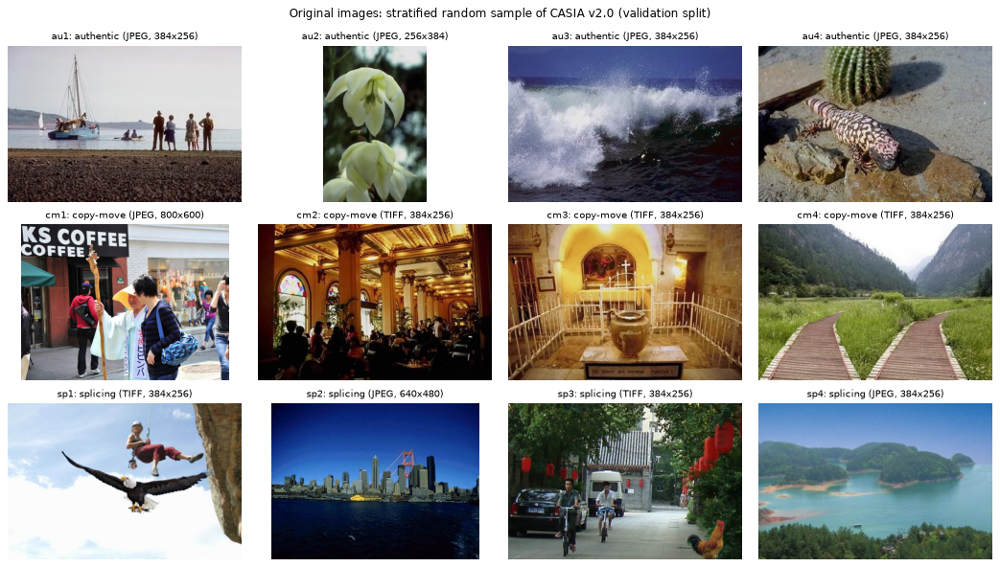

In [4]:
def sample_paths(name):
    r = S.loc[name]
    mask = r["mask"] if isinstance(r["mask"], str) and r["mask"] else None
    return IMAGES / r["file"], (IMAGES / mask if mask else None)

def show(images, titles, cmaps=None, suptitle=None, width=3.6, height=3.0, ncols=None):
    # one or more rows of titled panels
    n = len(images); ncols = ncols or n; nrows = -(-n // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(width * ncols, height * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, im, t, cm in zip(axes, images, titles, cmaps or [None] * n):
        ax.imshow(im, cmap=cm); ax.set_title(t); ax.axis("off")
    for ax in axes[n:]: ax.axis("off")
    if suptitle: fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout(h_pad=1.6); plt.show()

casia = [n for n in S.index if S.loc[n, "group"] == "casia"]
names12 = [n for n in casia if n not in ("cm_mirror", "sp_cat")]
orig = [load_rgb(sample_paths(n)[0]) for n in names12]
titles = [f"{n}: {S.loc[n,'kind']} ({S.loc[n,'format']}, {S.loc[n,'width']}x{S.loc[n,'height']})" for n in names12]
show(orig, titles, suptitle="Original images: stratified random sample of CASIA v2.0 (validation split)", ncols=4, width=3.3, height=2.5)

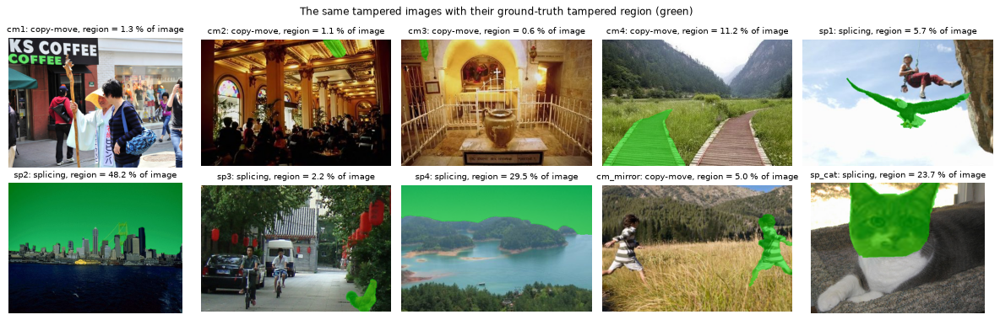

,kind,format,width,height,tampered_pct,note
name,,,,,,
au1,authentic,JPEG,384,256,0.00,stratified random sample (seed 42)
au2,authentic,JPEG,256,384,0.00,stratified random sample (seed 42)
au3,authentic,JPEG,384,256,0.00,stratified random sample (seed 42)
au4,authentic,JPEG,384,256,0.00,stratified random sample (seed 42)
cm1,copy-move,JPEG,800,600,1.32,stratified random sample (seed 42)
cm2,copy-move,TIFF,384,256,1.15,stratified random sample (seed 42)
cm3,copy-move,TIFF,384,256,0.59,stratified random sample (seed 42)
cm4,copy-move,TIFF,384,256,11.22,stratified random sample (seed 42)
sp1,splicing,TIFF,384,256,5.70,stratified random sample (seed 42)


In [5]:
tam = [n for n in casia if S.loc[n, "label"] == 1]
ov = []
for n in tam:
    p, mp = sample_paths(n)
    ov.append(E.overlay(load_rgb(p), np.asarray(Image.open(mp)) > 127, color=(0, 220, 0)))
show(ov, [f"{n}: {S.loc[n,'kind']}, region = {S.loc[n,'tampered_pct']:.1f} % of image" for n in tam],
     suptitle="The same tampered images with their ground-truth tampered region (green)", ncols=5, width=3.0, height=2.4)
display(S.loc[casia, ["kind", "format", "width", "height", "tampered_pct", "note"]])

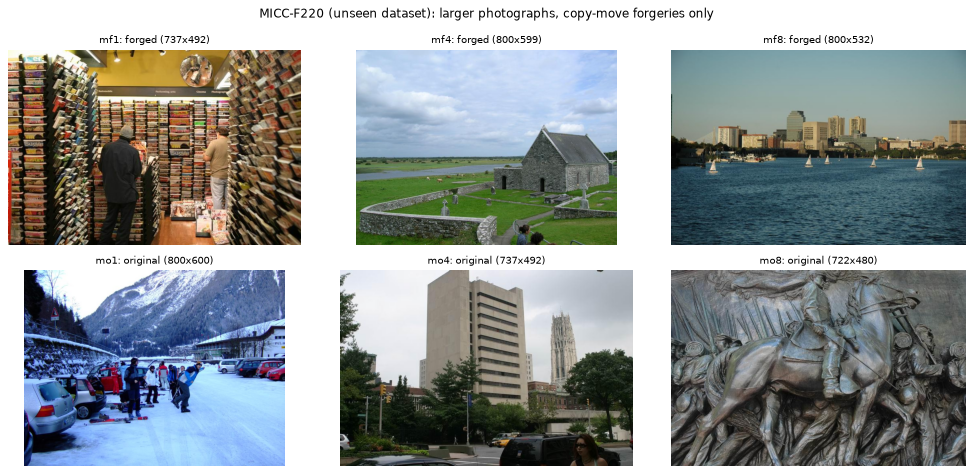

In [6]:
mic = [n for n in S.index if S.loc[n, "group"] == "micc"]
pick = ["mf1", "mf4", "mf8", "mo1", "mo4", "mo8"]
show([load_rgb(sample_paths(n)[0]) for n in pick],
     [f"{n}: {'forged' if S.loc[n,'label'] else 'original'} ({S.loc[n,'width']}x{S.loc[n,'height']})" for n in pick],
     suptitle="MICC-F220 (unseen dataset): larger photographs, copy-move forgeries only", ncols=3, width=4.2, height=3.0)

# 4. Final Image Processing Pipeline

The final pipeline has **eight forensic modules covering all five course categories**, preceded by a normalisation step and followed by a decision and a localisation stage. The diagram shows the order of processing.

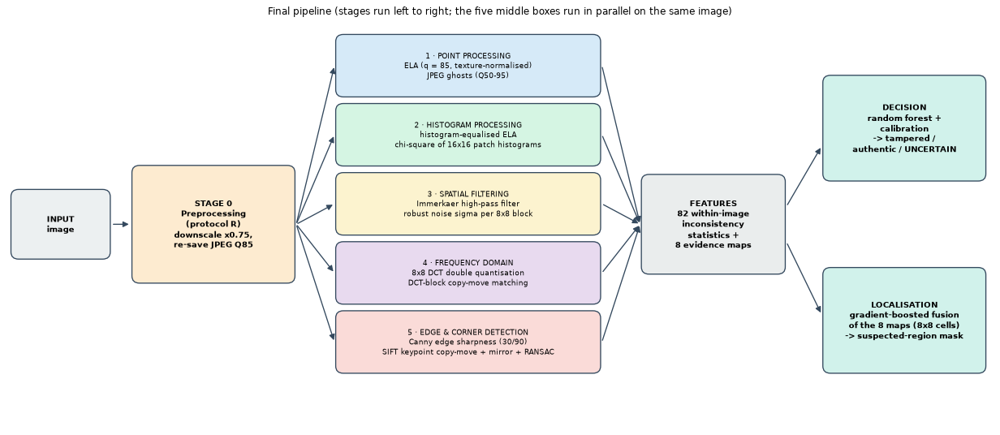

In [7]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def box(ax, x, y, w, h, text, fc, fs=8.6, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.12", fc=fc, ec="#34495E", lw=1.2))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, fontweight="bold" if bold else None, linespacing=1.35)

def arrow(ax, x0, y0, x1, y1):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=13, color="#34495E", lw=1.2))

fig, ax = plt.subplots(figsize=(15.5, 6.8)); ax.set_xlim(0, 15.5); ax.set_ylim(0, 6.8); ax.axis("off")
box(ax, 0.1, 2.85, 1.5, 1.1, "INPUT\nimage", "#ECF0F1", bold=True)
box(ax, 2.0, 2.45, 2.5, 1.9, "STAGE 0\nPreprocessing\n(protocol R)\ndownscale x0.75,\nre-save JPEG Q85", "#FDEBD0", bold=True)
cats = [("1 · POINT PROCESSING", "ELA (q = 85, texture-normalised)\nJPEG ghosts (Q50-95)", "#D6EAF8"),
        ("2 · HISTOGRAM PROCESSING", "histogram-equalised ELA\nchi-square of 16x16 patch histograms", "#D5F5E3"),
        ("3 · SPATIAL FILTERING", "Immerkaer high-pass filter\nrobust noise sigma per 8x8 block", "#FCF3CF"),
        ("4 · FREQUENCY DOMAIN", "8x8 DCT double quantisation\nDCT-block copy-move matching", "#E8DAEF"),
        ("5 · EDGE & CORNER DETECTION", "Canny edge sharpness (30/90)\nSIFT keypoint copy-move + mirror + RANSAC", "#FADBD8")]
ys = [5.55, 4.4, 3.25, 2.1, 0.95]
for (t, d, c), y in zip(cats, ys):
    box(ax, 5.2, y, 4.1, 0.98, f"{t}\n{d}", c, fs=8.2)
    arrow(ax, 4.55, 3.4, 5.15, y + 0.49); arrow(ax, 9.35, y + 0.49, 9.95, 3.4)
box(ax, 10.0, 2.6, 2.2, 1.6, "FEATURES\n82 within-image\ninconsistency\nstatistics +\n8 evidence maps", "#EAEDED", bold=True)
box(ax, 12.85, 4.15, 2.5, 1.7, "DECISION\nrandom forest +\ncalibration\n-> tampered /\nauthentic / UNCERTAIN", "#D1F2EB", bold=True)
box(ax, 12.85, 0.95, 2.5, 1.7, "LOCALISATION\ngradient-boosted fusion\nof the 8 maps (8x8 cells)\n-> suspected-region mask", "#D1F2EB", bold=True)
arrow(ax, 1.65, 3.4, 1.95, 3.4); arrow(ax, 12.25, 3.7, 12.8, 4.7); arrow(ax, 12.25, 3.1, 12.8, 1.9)
ax.set_title("Final pipeline (stages run left to right; the five middle boxes run in parallel on the same image)", fontsize=11)
plt.tight_layout(); plt.show()

| Stage | Category | Technique | Purpose | How it contributes to the objective |
|---|---|---|---|---|
| **0** | Preprocessing | Downscale ×0.75 and re-save as JPEG Q85 (*protocol R*) | Remove the file-format and global compression cues that leak the label | Makes every later result an honest measure of tampering evidence, not of the file container |
| **1a** | Point processing | **Error level analysis (ELA)**: \|I − JPEG<sub>85</sub>(I)\| per pixel, per-block mean divided by block texture | Expose regions that re-compress at a different error level | Pasted content has a different compression history; the strongest compression cue for splicing |
| **1b** | Point processing | **JPEG ghosts**: error curves over qualities 50–95 per 16×16 block | Find blocks last compressed at a different quality | A second, independent compression-history cue |
| **2** | Histogram processing | **Histogram equalisation** of the ELA residual, then **χ² distance** between 16×16 patch histograms | Make the faint ELA structure visible; flag patches whose error distribution differs | Turns "different error statistics" into a measurable per-patch distance |
| **3** | Spatial filtering | **Immerkær high-pass filter**, robust noise σ per 8×8 block over non-edge pixels | Estimate local sensor noise | Content from another camera carries a different noise level |
| **4a** | Frequency domain | **8×8 DCT double quantisation** (periodicity tested with a permutation test) | Detect that a region was JPEG-compressed twice | Regions pasted after the first compression lack the periodic coefficient pattern |
| **4b** | Frequency domain | **DCT-block copy-move**: overlapping 16×16 blocks described by 9 DCT coefficients, shift voting | Find duplicated blocks | Complements keypoint matching |
| **5a** | Edge detection | **Canny** (30/90) and edge sharpness (gradient ÷ local contrast) | Detect unnaturally hard or feathered boundaries | Pasted objects often have different edge sharpness |
| **5b** | Corner / keypoint detection | **SIFT keypoints** matched against the image and its mirror image, verified with **RANSAC** | Find duplicated regions, including flipped, rotated and scaled copies | The strongest single technique for copy-move |
| **6** | Fusion and decision | 82 within-image statistics → random forest → isotonic calibration → *uncertain* band | Combine all evidence into P(tampered) and abstain when unsure | Turns eight maps into one reliable, calibrated decision |
| **7** | Fusion and localisation | Gradient boosting on 8×8 cells of the 8 maps, then morphology | Produce the suspected-region mask | Shows where the image was changed; suppressed when the verdict is *authentic* |

Techniques from the Phase 1 proposal that did **not** survive our experiments (Harris corners, the 3×3 Laplacian filter, 32×32 patches, Canny 50/150) are discussed in Sections 6 and 8.

### 4.1 Which version is final
**The pipeline described in this notebook is the final version, and it is frozen.** It was fixed before the held-out test set was used (24 September 2026). The test set was then evaluated once, and nothing in the pipeline was changed afterwards: the eight feature modules, their parameters (`config.yaml`) and all trained models are the ones that produced the test results in Section 7.5. The check below proves it: it compares the code and model files in the project folder with the fingerprints recorded at the time of the test evaluation.

Our Phase 2 notebook called the pipeline frozen and, in its *Next steps*, also listed things we planned to improve. That was ambiguous, so here is what became of each item. **None of the items below changed the frozen pipeline.**

| Phase 2 item | What happened | Where |
|---|---|---|
| Final held-out test evaluation, without further tuning | Done once (run no. 1) on the frozen pipeline, and not repeated | 7.5 |
| Robustness tests (re-compression, resizing, blur, noise, social-media upload) and a second dataset (MICC-F220) | Done as **evaluation only**, with the frozen models | 7.4, 7.6 |
| Optional deep-learning baseline | Trained and evaluated once, **only for comparison** | 7.6 |
| Better localisation of small regions | **Not changed.** It remains a limitation (pixel F1 0.04 for regions below 1 % of the image) | 7.7, 8 |
| Fewer copy-move false alarms on repeated structure | **Not changed.** It remains a limitation (all 13 confident false alarms in the test set) | 7.7, 8 |
| Decide whether the weakest steps (histogram χ², DCT under resampling) stay | **All eight modules kept.** Under the final protocol, removing either one changes the AUC by less than 0.001 (leave-one-out), so removing them would not help. Changing the pipeline after the one-time test would also have invalidated that test | `supporting/phase5_ablations.csv`, 8 |

The improvements in Section 8 (*Possible future improvements*) are ideas for future work. They are **not** part of the submitted pipeline.

In [8]:
# ---- fingerprint check: is the pipeline in the project folder the one evaluated on the test set? ----------
import hashlib
from forgery.pipeline import feature_code_sha1, resolved_params

sha1 = lambda p: hashlib.sha1(Path(p).read_bytes()).hexdigest()
LOG = [json.loads(l) for l in Path("supporting/test_runs.log").read_text().splitlines() if l.strip()]
REC = next(e for e in LOG if e["event"] == "start")                       # fingerprints recorded when the test set was evaluated
TEST_SUMMARY = json.loads(Path("supporting/phase7_summary.json").read_text())

rows = []                                                                   # (item, value here, value recorded, same?)
def add(item, here, recorded, show=lambda v: v[:12]):
    rows.append({"Item": item, "In the project folder": show(here), "Recorded at the test evaluation": show(recorded), "Same?": "yes" if here == recorded else "NO"})

add("Feature-module source code (8 techniques + image I/O)", feature_code_sha1(), REC["feature_code_sha1"])
for name in ("forgery", "type", "localizer"):
    add(f"Trained model: models/{name}_R.joblib", sha1(f"models/{name}_R.joblib"), REC["inputs_sha1"][f"models/{name}_R.joblib"])
if LIVE:                                                                    # the parameters stored inside the trained model
    add("Tuned parameters (config.yaml) = parameters the model was trained with",
        json.dumps(resolved_params(cfg, "R"), sort_keys=True), json.dumps(M.forgery.meta["feature_params"], sort_keys=True),
        show=lambda v: hashlib.sha1(v.encode()).hexdigest()[:12])
if Path("data/test_split.sha256").exists():                                 # present when the full project folder is used
    add("Frozen test split (data/test_split.sha256)", Path("data/test_split.sha256").read_text().split()[0], TEST_SUMMARY["test_split_sha256"])

check = pd.DataFrame(rows)
display(Markdown(check.to_markdown(index=False)))
print(f"Test evaluation: run no. {REC['run_number']} on {REC['time'][:10]}; {sum(e['event'] == 'start' for e in LOG)} run(s) of the test set in total.")
assert (check["Same?"] == "yes").all(), "the pipeline in the project folder differs from the one evaluated on the test set"
print("All fingerprints match: the pipeline in this notebook is the frozen version that produced the test results in Section 7.5.")

| Item                                                                   | In the project folder   | Recorded at the test evaluation   | Same?   |
|:-----------------------------------------------------------------------|:------------------------|:----------------------------------|:--------|
| Feature-module source code (8 techniques + image I/O)                  | a057618b304e            | a057618b304e                      | yes     |
| Trained model: models/forgery_R.joblib                                 | 32ff596dcab4            | 32ff596dcab4                      | yes     |
| Trained model: models/type_R.joblib                                    | 96c5cb5298b9            | 96c5cb5298b9                      | yes     |
| Trained model: models/localizer_R.joblib                               | ec934de032fd            | ec934de032fd                      | yes     |
| Tuned parameters (config.yaml) = parameters the model was trained with | e0d37274f40f            | e0d37274f40f                      | yes     |

Test evaluation: run no. 1 on 2026-09-24; 1 run(s) of the test set in total.
All fingerprints match: the pipeline in this notebook is the frozen version that produced the test results in Section 7.5.


# 5. Complete Python Implementation

The implementation uses NumPy, OpenCV (`cv2`), Matplotlib and scikit-learn.
- **Sections 5.2–5.7:** each stage is shown here as compact, commented code and checked against the packaged module in `src/forgery/` that the final pipeline uses.
- **Section 5.8:** the complete pipeline, `run_pipeline()`, chains the eight packaged modules (the tuned versions of these stage functions) with the trained decision and localisation models, and is run on all sample images.

### 5.1 Utilities and Stage 0 — preprocessing (protocol R)

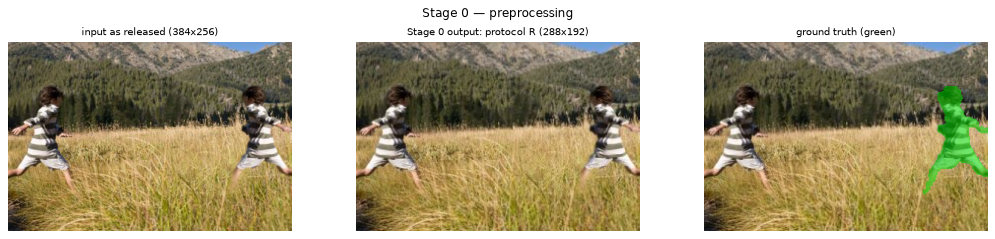

In [9]:
def luma(img):                                   # ITU-R BT.601 luminance, float32
    x = img.astype(np.float32)
    return 0.299 * x[..., 0] + 0.587 * x[..., 1] + 0.114 * x[..., 2]

def to_blocks(x, b):                             # (H, W) -> (H//b, W//b, b*b): non-overlapping b x b blocks
    h, w = (x.shape[0] // b) * b, (x.shape[1] // b) * b
    return x[:h, :w].reshape(h // b, b, w // b, b).transpose(0, 2, 1, 3).reshape(h // b, w // b, b * b)

def upsample(block_map, shape, b):               # block map -> image size (for display)
    return cv2.resize(np.nan_to_num(block_map).astype(np.float32), (shape[1], shape[0]), interpolation=cv2.INTER_NEAREST)

def stage0_protocol_R(rgb, factor=0.75, quality=85):
    # STAGE 0: downscale with area interpolation, then JPEG re-encode (Q85, 4:2:0). Removes file-format cues.
    small = cv2.resize(rgb, (round(rgb.shape[1] * factor), round(rgb.shape[0] * factor)), interpolation=cv2.INTER_AREA)
    return jpeg_roundtrip(small, quality)

def load_sample(name):
    # raw image, protocol-R image, ground-truth mask in protocol-R geometry (None for authentic images)
    p, mp = sample_paths(name)
    raw = load_rgb(p)
    gt = protocol_mask(np.asarray(Image.open(mp)) > 127, "R", cfg) if mp else None
    return raw, stage0_protocol_R(raw), gt

raw, img_cm, gt_cm = load_sample("cm_mirror")             # copy-move example (the copy is mirrored)
_, img_sp, gt_sp = load_sample("sp_cat")                  # splicing example
assert np.array_equal(img_cm, apply_protocol(raw, "R", cfg))      # identical to the packaged implementation
show([raw, img_cm, E.overlay(img_cm, gt_cm, color=(0, 220, 0))],
     [f"input as released ({raw.shape[1]}x{raw.shape[0]})", f"Stage 0 output: protocol R ({img_cm.shape[1]}x{img_cm.shape[0]})",
      "ground truth (green)"], suptitle="Stage 0 — preprocessing", width=4.4)

### 5.2 Stage 1 — Point processing: ELA and JPEG ghosts
ELA is a **point operation**: every output pixel depends only on the same pixel before and after one JPEG re-save. Because texture alone also produces error, the block mean is divided by the block's texture. JPEG ghosts repeat the re-save over a ladder of qualities and compare each block's error curve with the image's median curve.

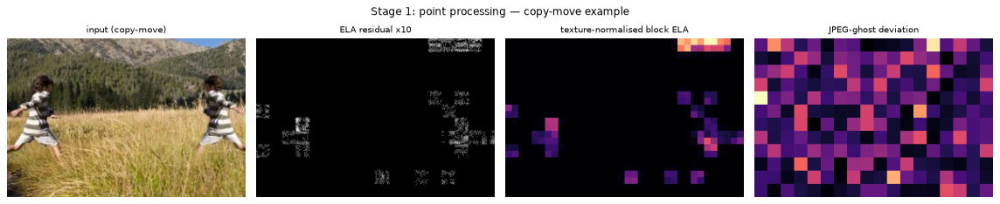

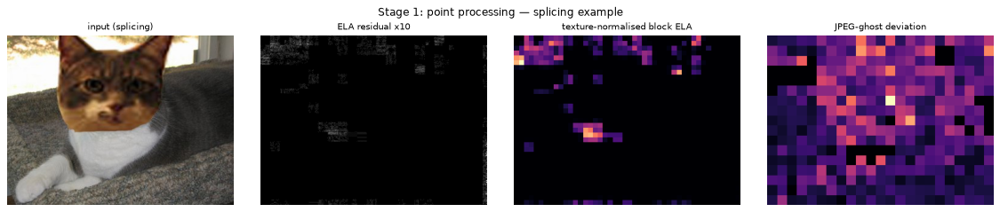

agreement with the packaged modules (max |difference|): ELA normalised block map 2.9474066555457146e-09 | JPEG-ghost deviation map 0.0


In [10]:
def stage1_ela(img, q=85, block=8, c=16.0):
    # ELA residual |I - JPEG_q(I)| (mean over RGB), then block mean divided by block texture (+ constant c)
    resid = np.abs(img.astype(np.int16) - jpeg_roundtrip(img, q).astype(np.int16)).mean(axis=2)
    ela_block = to_blocks(resid, block).mean(axis=2)
    texture = to_blocks(luma(img), block).std(axis=2)
    return resid, ela_block / (texture + c)

def stage1_ghost(img, qualities=range(50, 100, 5), block=16, min_std=4.0):
    # JPEG ghosts: per-block squared error at each quality; min-max normalise each curve; distance to the median curve
    x = img.astype(np.float32)
    curves = np.stack([to_blocks(((x - jpeg_roundtrip(img, q).astype(np.float32)) ** 2).mean(axis=2), block).mean(axis=2)
                       for q in qualities], axis=-1)
    norm = (curves - curves.min(-1, keepdims=True)) / (np.ptp(curves, axis=-1, keepdims=True) + 1e-6)
    gb = to_blocks(luma(img), block)
    valid = (gb.std(axis=2) >= min_std) & (gb.mean(axis=2) > 4) & (gb.mean(axis=2) < 251)      # skip flat / clipped blocks
    median_curve = np.median(norm[valid].reshape(-1, norm.shape[-1]), axis=0)
    return np.abs(norm - median_curve).mean(axis=-1), valid

for name, im in (("copy-move", img_cm), ("splicing", img_sp)):
    resid, norm_block = stage1_ela(im)
    dev, ok = stage1_ghost(im)
    show([im, np.clip(resid * 10, 0, 255), upsample(norm_block, im.shape, 8), upsample(np.where(ok, dev, 0), im.shape, 16)],
         [f"input ({name})", "ELA residual x10", "texture-normalised block ELA", "JPEG-ghost deviation"],
         [None, "gray", "magma", "magma"], suptitle=f"Stage 1: point processing — {name} example", width=3.6)

ela_mod = [m for m in MODULES if m.name == "ela"][0]
gh_ref = [m for m in MODULES if m.name == "jpeg_ghost"][0].maps(img_cm)["deviation"]
print("agreement with the packaged modules (max |difference|): ELA normalised block map",
      float(np.abs(stage1_ela(img_cm)[1] - ela_mod.maps(img_cm)["norm_block"]).max()), "| JPEG-ghost deviation map",
      float(np.abs(stage1_ghost(img_cm)[0] - gh_ref).max()))

### 5.3 Stage 2 — Histogram processing: equalisation and patch-histogram χ²
The ELA residual is low-contrast (almost every value is 0–2), so it is **histogram-equalised**. Each 16×16 patch's histogram is then compared with the image's typical patch histogram using the **χ² distance**.

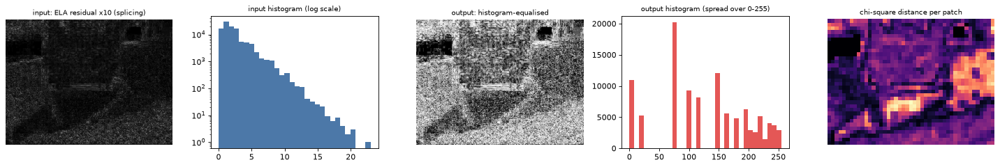

agreement with the packaged histogram module (max |difference|): equalised image 0 | chi-square map 6.75597456867294e-08


In [11]:
def stage2_histogram(img, q=75, patch=16, bins=16):
    # equalise the ELA residual, then chi-square distance of each patch histogram to the typical patch histogram
    resid = np.abs(img.astype(np.int16) - jpeg_roundtrip(img, q).astype(np.int16)).mean(axis=2)
    hi = max(np.percentile(resid, 99.5), 1e-3)                                 # contrast stretch ...
    eq = cv2.equalizeHist(np.clip(resid / hi * 255, 0, 255).astype(np.uint8))   # ... then histogram equalisation
    qbin = (eq.astype(np.int32) * bins) // 256
    g, step = luma(img), patch // 2                                            # 50 % overlapping patches
    hists, valid, ny, nx = [], [], 0, 0
    for y in range(0, eq.shape[0] - patch + 1, step):
        nx = 0
        for x in range(0, eq.shape[1] - patch + 1, step):
            hists.append(np.bincount(qbin[y:y + patch, x:x + patch].ravel(), minlength=bins) / patch ** 2)
            gp = g[y:y + patch, x:x + patch]
            valid.append(gp.std() >= 2.0 and 4 < gp.mean() < 251)             # skip flat / clipped patches
            nx += 1
        ny += 1
    h, valid = np.array(hists), np.array(valid)
    ref = h[valid].mean(axis=0) if valid.any() else h.mean(axis=0)
    chi2 = 0.5 * ((h - ref) ** 2 / (h + ref + 1e-12)).sum(axis=1)
    return eq, chi2.reshape(ny, nx), valid.reshape(ny, nx), resid

hist_mod = [m for m in MODULES if m.name == "histogram"][0]
eq, chi2, vld, resid = stage2_histogram(img_sp)
fig, ax = plt.subplots(1, 5, figsize=(18, 3.1))
ax[0].imshow(np.clip(resid * 10, 0, 255), cmap="gray"); ax[0].set_title("input: ELA residual x10 (splicing)")
ax[1].hist(resid.ravel(), bins=30, color="#4C78A8"); ax[1].set_yscale("log"); ax[1].set_title("input histogram (log scale)")
ax[2].imshow(eq, cmap="gray"); ax[2].set_title("output: histogram-equalised")
ax[3].hist(eq.ravel(), bins=32, color="#E45756"); ax[3].set_title("output histogram (spread over 0-255)")
ax[4].imshow(np.where(vld, chi2, 0), cmap="magma"); ax[4].set_title("chi-square distance per patch")
for a in (ax[0], ax[2], ax[4]): a.axis("off")
plt.tight_layout(); plt.show()
ref = hist_mod.maps(img_sp)
print("agreement with the packaged histogram module (max |difference|): equalised image",
      int(np.abs(eq.astype(int) - ref["equalized"].astype(int)).max()), "| chi-square map",
      float(np.abs(chi2 - ref["distance"]).max()))

### 5.4 Stage 3 — Spatial filtering: local noise level
A **high-pass spatial filter** (Immerkær's 3×3 kernel, which cancels edges and linear ramps) removes most image content and leaves noise. The noise level of each 8×8 block is estimated robustly (1.4826 × median absolute residual) from **non-edge, non-flat, unclipped pixels only**, because edges leak content into the residual.

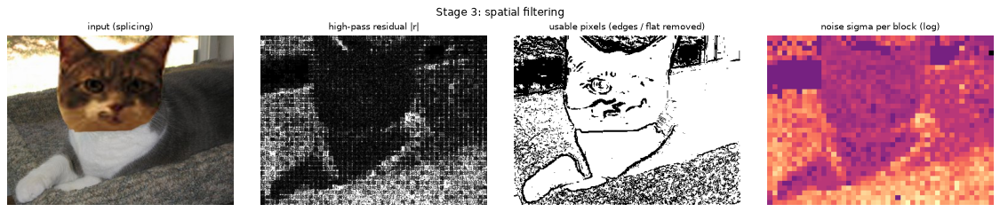

agreement with the packaged noise module (max |difference| of the block map): 0.0


In [12]:
IMMERKAER = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)

def stage3_noise(img, block=8, edge_quantile=0.8, min_pixels=16, min_std=2.0):
    g = luma(img)
    resid = cv2.filter2D(g, cv2.CV_32F, IMMERKAER, borderType=cv2.BORDER_REFLECT)          # spatial high-pass filter
    grad = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
    usable = (grad <= np.quantile(grad, edge_quantile)) & (g > 4) & (g < 251)               # drop edges and clipped pixels
    m3 = cv2.blur(g, (3, 3)); usable &= (cv2.blur(g * g, (3, 3)) - m3 * m3) > 0.01          # drop perfectly flat areas
    rb, ub = to_blocks(np.abs(resid), block), to_blocks(usable, block)
    med = np.nanmedian(np.where(ub, rb, np.nan), axis=2)                                    # robust per-block level
    gb = to_blocks(g, block)
    ok = (ub.sum(axis=2) >= min_pixels) & (gb.std(axis=2) >= min_std) & (gb.mean(axis=2) > 4) & (gb.mean(axis=2) < 251)
    return resid, usable, np.log(np.where(ok, 1.4826 * np.nan_to_num(med), np.nan) + 0.1)

resid, usable, log_sigma = stage3_noise(img_sp)
show([img_sp, np.clip(np.abs(resid), 0, 30), usable, upsample(log_sigma, img_sp.shape, 8)],
     ["input (splicing)", "high-pass residual |r|", "usable pixels (edges / flat removed)", "noise sigma per block (log)"],
     [None, "gray", "gray", "magma"], suptitle="Stage 3: spatial filtering", width=3.6)
noise_mod = [m for m in MODULES if m.name == "noise"][0]
ref = noise_mod.maps(img_sp)["log_sigma"]
print("agreement with the packaged noise module (max |difference| of the block map):", float(np.nanmax(np.abs(log_sigma - ref))))

### 5.5 Stage 4 — Frequency domain: DCT double quantisation and block copy-move
JPEG quantises the 8×8 **DCT** coefficients, so a coefficient's histogram concentrates on multiples of the quantisation step. After a **second** compression the histogram shows a regular comb of peaks and gaps, which a region pasted in after the first compression lacks. The figure demonstrates the effect on authentic images (single vs double compression) with a simple measure, the share of empty bins in the central histogram; the packaged module tests the periodicity per frequency with a permutation test, which gives a calibrated false-positive rate.

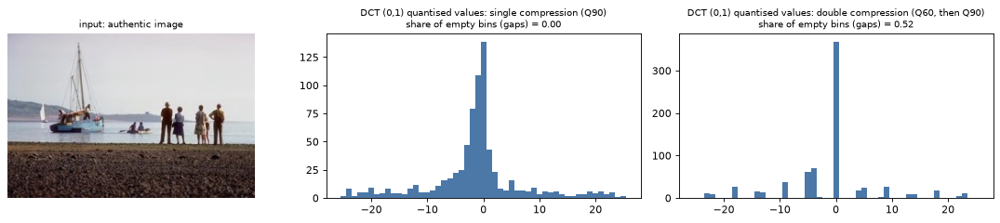

,"gap share, single compression","gap share, double compression"
image,,
au1,0.0,0.52
au2,0.0,0.28
au3,0.0,0.40
au4,0.0,0.36


In [13]:
def dct_coefficients(img, k=(0, 1), step=1.0):
    # k-th DCT coefficient of every 8x8 luminance block, divided by the quantisation step
    Y = luma(img) - 128
    h, w = (Y.shape[0] // 8) * 8, (Y.shape[1] // 8) * 8
    c = np.array([cv2.dct(Y[i:i + 8, j:j + 8])[k] for i in range(0, h, 8) for j in range(0, w, 8)])
    return np.rint(c / step)

def gap_share(q, half=12):
    # share of EMPTY bins in the central part of the histogram of quantised values: ~0 after single compression;
    # double compression leaves regular gaps (the comb)
    h = np.bincount((q[np.abs(q) <= 25] + 25).astype(int), minlength=51)
    return float((h[25 - half:25 + half + 1] == 0).mean())

authentic, _, _ = load_sample("au1")
base = cv2.resize(authentic, None, fx=0.75, fy=0.75, interpolation=cv2.INTER_AREA)        # erase the original JPEG grid
single, double = jpeg_roundtrip(base, 90), jpeg_roundtrip(jpeg_roundtrip(base, 60), 90)
step90 = ijg_table(90).reshape(8, 8)[0, 1]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.1))
ax[0].imshow(base); ax[0].set_title("input: authentic image"); ax[0].axis("off")
for a, im, t in ((ax[1], single, "single compression (Q90)"), (ax[2], double, "double compression (Q60, then Q90)")):
    q = dct_coefficients(im, step=step90)
    a.hist(q[np.abs(q) <= 25], bins=np.arange(-25.5, 26.5), color="#4C78A8")
    a.set_title(f"DCT (0,1) quantised values: {t}\nshare of empty bins (gaps) = {gap_share(q):.2f}")
plt.tight_layout(); plt.show()

rows = []                                                       # the same effect on four authentic images
for n in ("au1", "au2", "au3", "au4"):
    b = cv2.resize(load_sample(n)[0], None, fx=0.75, fy=0.75, interpolation=cv2.INTER_AREA)
    rows.append({"image": n, "gap share, single compression": gap_share(dct_coefficients(jpeg_roundtrip(b, 90), step=step90)),
                 "gap share, double compression": gap_share(dct_coefficients(jpeg_roundtrip(jpeg_roundtrip(b, 60), 90), step=step90))})
display(pd.DataFrame(rows).set_index("image").round(2))

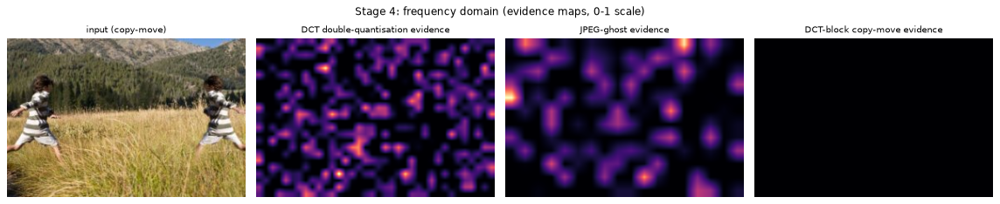

In [14]:
# the packaged evidence maps of the frequency-domain stage on the copy-move example
dq_mod = [m for m in MODULES if m.name == "dct_dq"][0]; cb_mod = [m for m in MODULES if m.name == "cm_block"][0]
gh_mod = [m for m in MODULES if m.name == "jpeg_ghost"][0]
show([img_cm, dq_mod.extract(img_cm).evidence_map, gh_mod.extract(img_cm).evidence_map, cb_mod.extract(img_cm).evidence_map],
     ["input (copy-move)", "DCT double-quantisation evidence", "JPEG-ghost evidence", "DCT-block copy-move evidence"],
     [None, "magma", "magma", "magma"], suptitle="Stage 4: frequency domain (evidence maps, 0-1 scale)", width=3.6)

### 5.6 Stage 5 — Edge and corner detection: Canny sharpness and SIFT copy-move
- **Canny** finds edges; at each edge pixel we measure *sharpness* (gradient ÷ local contrast). A pasted object can have unnaturally hard or feathered boundaries.
- For **copy-move**, SIFT keypoints are matched against the *same image* (nearest non-self neighbour with a ratio test), and the matches are verified with **RANSAC**: only pairs explained by one consistent geometric transform survive. The final module additionally matches against the **mirror image**, because some copies are flipped.

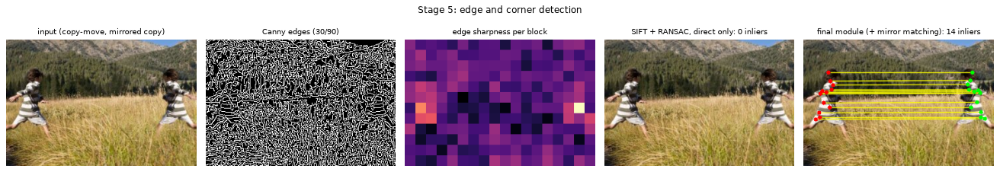

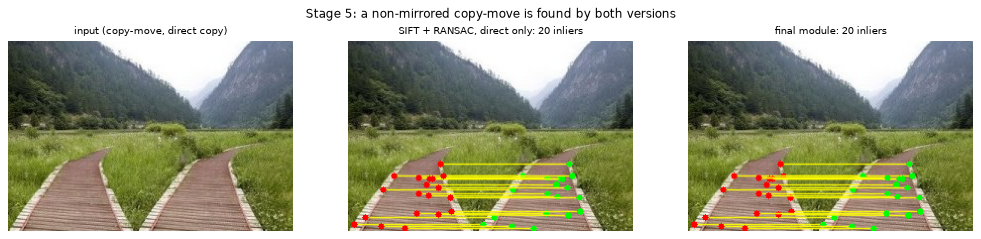

In [15]:
def stage5_edges(img, low=30, high=90, block=16):
    # Canny edges; sharpness = gradient / local contrast at each edge pixel; median per block
    g = luma(img)
    edges = cv2.Canny(np.clip(g, 0, 255).astype(np.uint8), low, high, L2gradient=True) > 0
    grad = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1)) / 8.0
    contrast = cv2.dilate(g, np.ones((5, 5), np.uint8)) - cv2.erode(g, np.ones((5, 5), np.uint8))
    sharp = np.where(edges, grad / (contrast + 1.0), np.nan)
    return edges, np.nanmedian(np.where(to_blocks(edges, block).sum(2)[..., None] > 0, to_blocks(sharp, block), np.nan), axis=2)

def stage5_sift_direct(img, ratio=0.6, min_shift=20, ransac_px=3.0):
    # SIFT keypoints matched against the same image + RANSAC (direct copies only)
    g = np.clip(luma(img), 0, 255).astype(np.uint8)
    kps, desc = cv2.SIFT_create(contrastThreshold=0.01).detectAndCompute(g, None)
    pts = np.array([k.pt for k in kps])
    pairs = set()
    for i, ms in enumerate(cv2.BFMatcher(cv2.NORM_L2).knnMatch(desc, desc, k=3)):
        ms = [m for m in ms if m.trainIdx != i]                                # drop the self-match
        if len(ms) >= 2 and ms[0].distance < ratio * ms[1].distance:           # ratio test
            j = ms[0].trainIdx
            if np.hypot(*(pts[i] - pts[j])) > min_shift:
                pairs.add((i, j) if tuple(pts[i]) <= tuple(pts[j]) else (j, i))    # orient left point first
    if len(pairs) < 3:
        return np.zeros((0, 2)), np.zeros((0, 2)), np.zeros(0, bool)
    idx = np.array(sorted(pairs)); src, dst = pts[idx[:, 0]], pts[idx[:, 1]]
    _, inl = cv2.estimateAffine2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=ransac_px)
    return src, dst, (inl.ravel().astype(bool) if inl is not None else np.zeros(len(src), bool))

def draw_matches(img, src, dst, inl):
    vis = img.copy()
    for s, d in zip(src[inl], dst[inl]):
        cv2.line(vis, tuple(int(v) for v in s), tuple(int(v) for v in d), (255, 255, 0), 1, cv2.LINE_AA)
        cv2.circle(vis, tuple(int(v) for v in s), 3, (255, 0, 0), -1); cv2.circle(vis, tuple(int(v) for v in d), 3, (0, 255, 0), -1)
    return vis

edges, sharp = stage5_edges(img_cm)
kp_mod = [m for m in MODULES if m.name == "cm_keypoint"][0]
s1, d1, i1 = stage5_sift_direct(img_cm)                                    # direct matching only (this copy is mirrored)
m_final = kp_mod.match(img_cm)                                              # final module: direct + mirrored matching
show([img_cm, edges, upsample(sharp, img_cm.shape, 16), draw_matches(img_cm, s1, d1, i1),
      draw_matches(img_cm, m_final["src"], m_final["dst"], m_final["inliers"])],
     ["input (copy-move, mirrored copy)", "Canny edges (30/90)", "edge sharpness per block",
      f"SIFT + RANSAC, direct only: {int(i1.sum())} inliers", f"final module (+ mirror matching): {int(m_final['inliers'].sum())} inliers"],
     [None, "gray", "magma", None, None], suptitle="Stage 5: edge and corner detection", width=3.3)

cm_direct = load_sample("cm4")[1]                                          # a copy-move whose copy is NOT mirrored
s2, d2, i2 = stage5_sift_direct(cm_direct); m2 = kp_mod.match(cm_direct)
show([cm_direct, draw_matches(cm_direct, s2, d2, i2), draw_matches(cm_direct, m2["src"], m2["dst"], m2["inliers"])],
     ["input (copy-move, direct copy)", f"SIFT + RANSAC, direct only: {int(i2.sum())} inliers", f"final module: {int(m2['inliers'].sum())} inliers"],
     suptitle="Stage 5: a non-mirrored copy-move is found by both versions", width=4.3)

### 5.7 Summary of the stage outputs on one image

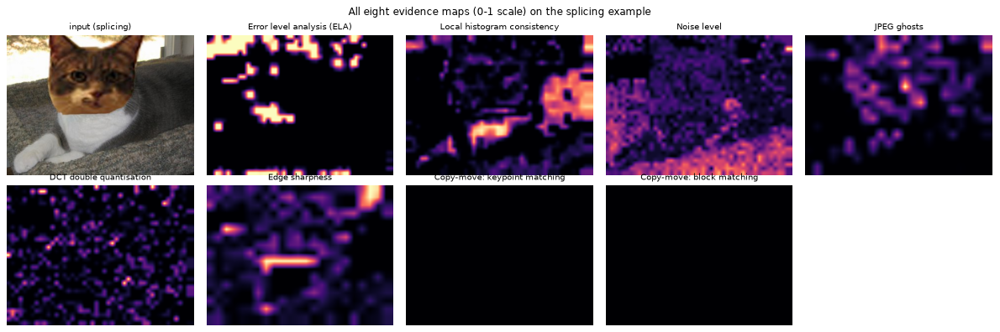

In [16]:
maps = {m.name: m.extract(img_sp).evidence_map for m in MODULES}
show([img_sp] + [maps[k] for k in ("ela", "histogram", "noise", "jpeg_ghost", "dct_dq", "edges", "cm_keypoint", "cm_block")],
     ["input (splicing)"] + [E.MODULES[k][0] for k in ("ela", "histogram", "noise", "jpeg_ghost", "dct_dq", "edges", "cm_keypoint", "cm_block")],
     [None] + ["magma"] * 8, suptitle="All eight evidence maps (0-1 scale) on the splicing example", ncols=5, width=3.0, height=2.5)

### 5.8 The complete pipeline: `run_pipeline()`
Stage 0 → the eight forensic modules (Stages 1–5) → 82 features → calibrated random forest → verdict (and forgery type) → learned fusion of the evidence maps → suspected-region mask. This is the same computation as `forgery.pipeline.detect()`, written out here step by step.

In [17]:
def run_pipeline(img):
    # COMPLETE PIPELINE on a protocol-R image (Stage 0 has already been applied by load_sample)
    feats, maps = {}, {}
    for m in MODULES:                                        # Stages 1-5: eight forensic modules -> maps + features
        out = m.extract(img)
        maps[m.name] = out.evidence_map
        feats.update({f"{m.name}.{k}": float(v) for k, v in out.features.items()})
    x = np.array([[feats[n] for n in M.forgery.feature_names_]])
    p = float(M.forgery.predict_proba(x)[0, 1])             # Stage 6: calibrated random forest -> P(tampered)
    verdict = verdict_from_probability(p, cfg, M.band)       #          tampered / authentic / uncertain (band 0.5 +- 0.24)
    kind = None
    if verdict == "tampered":                                #          likely forgery type
        xt = np.array([[feats[n] for n in M.type.feature_names_]])
        kind = "copy-move" if M.type.predict_proba(xt)[0, 1] >= 0.5 else "splicing"
    prob, mask = M.localizer.predict(maps, img.shape[:2])    # Stage 7: learned fusion of the 8 maps -> probability + mask
    fused = np.clip(prob, 0, 1).astype(np.float32)
    if verdict == "authentic":                               #          gating: no region for an authentic verdict
        mask, fused = np.zeros_like(mask), np.zeros_like(fused)
    return SimpleNamespace(feats=feats, maps=maps, fused=fused, mask=mask, p=p, verdict=verdict, kind=kind)

def from_cache(name):
    c, z = CACHE[name], np.load(f"precomputed/{name}.npz")
    maps = {k: z[k].astype(np.float32) for k in z.files if k not in ("mask", "fused")} or None
    return SimpleNamespace(feats=c["features"], maps=maps, fused=z["fused"].astype(np.float32), mask=z["mask"],
                           p=c["confidence"], verdict=c["verdict"], kind=c["likely_type"])

RESULTS = {}
def get_result(name):
    # live pipeline when the models load here, otherwise the cached output of the same pipeline
    if name not in RESULTS:
        RESULTS[name] = run_pipeline(load_sample(name)[1]) if LIVE else from_cache(name)
    return RESULTS[name]

if LIVE:                                                      # check: identical to the packaged detect() implementation
    diffs = []
    for n in ("cm_mirror", "sp_cat", "au1", "cm4"):
        ref = E.analyse(sample_paths(n)[0], M, cfg)
        mine = get_result(n)
        diffs.append((n, abs(mine.p - ref.confidence), mine.verdict == ref.verdict, bool((mine.mask == ref.mask).all())))
    display(pd.DataFrame(diffs, columns=["image", "|P - P(detect())|", "same verdict", "same mask"]))

,image,|P - P(detect())|,same verdict,same mask
0,cm_mirror,0.0,True,True
1,sp_cat,0.0,True,True
2,au1,0.0,True,True
3,cm4,0.0,True,True


# 6. Experimental Results and Parameter Comparison

We compare the parameters that matter most for the final pipeline. The per-technique settings (ELA quality, patch size, kernel, Canny thresholds, Harris vs SIFT) were chosen in Phase 2 on a 2,400-image training sample and scored on 1,000 validation images with two objective numbers: **image AUC** (how well the technique's features alone separate tampered from authentic images) and **pixel AUC** (how well its evidence map ranks tampered pixels against the ground-truth masks). Here we test the choices that shape the *final* pipeline, on multiple images, and refresh the per-technique evidence.

### 6.1 Preprocessing: protocol A (files as released) vs R (re-encoded and resampled)
ELA of an authentic JPEG and of a tampered TIFF, as released and after Stage 0:

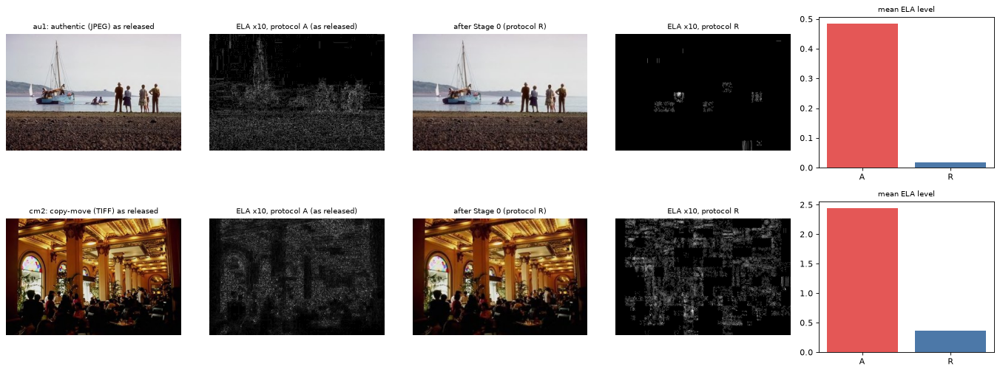

,kind,format,"mean ELA, A","mean ELA, R"
image,,,,
au1,authentic,JPEG,0.483,0.016
cm2,copy-move,TIFF,2.436,0.366


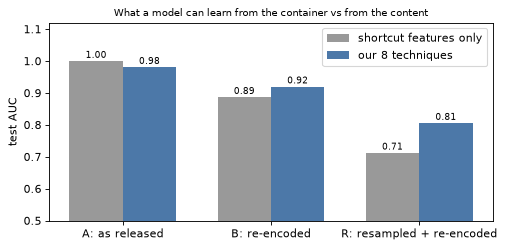

In [18]:
fig, ax = plt.subplots(2, 5, figsize=(17, 6.4))
rows = []
for r, name in enumerate(("au1", "cm2")):                                  # an authentic JPEG, a tampered TIFF
    raw, imgR, _ = load_sample(name)
    elaA, elaR = stage1_ela(raw)[0], stage1_ela(imgR)[0]
    ax[r, 0].imshow(raw); ax[r, 0].set_title(f"{name}: {S.loc[name,'kind']} ({S.loc[name,'format']}) as released")
    ax[r, 1].imshow(np.clip(elaA * 10, 0, 255), cmap="gray"); ax[r, 1].set_title("ELA x10, protocol A (as released)")
    ax[r, 2].imshow(imgR); ax[r, 2].set_title("after Stage 0 (protocol R)")
    ax[r, 3].imshow(np.clip(elaR * 10, 0, 255), cmap="gray"); ax[r, 3].set_title("ELA x10, protocol R")
    ax[r, 4].bar(["A", "R"], [elaA.mean(), elaR.mean()], color=["#E45756", "#4C78A8"]); ax[r, 4].set_title("mean ELA level")
    for a in ax[r, :4]: a.axis("off")
    rows.append({"image": name, "kind": S.loc[name, "kind"], "format": S.loc[name, "format"],
                 "mean ELA, A": elaA.mean(), "mean ELA, R": elaR.mean()})
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("image"))

tc = pd.DataFrame(MET["test_classification"])
tc = tc[(tc.model == "rf") & tc.feature_set.isin(["shortcuts", "forensic_all"])]
piv = tc.pivot_table(index="protocol", columns="feature_set", values="auc").loc[["A", "B", "R"]]
fig, ax = plt.subplots(figsize=(6.5, 3.2)); x = np.arange(3)
ax.bar(x - 0.18, piv["shortcuts"], 0.36, label="shortcut features only", color="#999999")
ax.bar(x + 0.18, piv["forensic_all"], 0.36, label="our 8 techniques", color="#4C78A8")
ax.set_xticks(x, ["A: as released", "B: re-encoded", "R: resampled + re-encoded"]); ax.set_ylim(0.5, 1.12)
ax.set_ylabel("test AUC"); ax.legend(loc="upper right"); ax.set_title("What a model can learn from the container vs from the content")
for xi, (a_, b_) in enumerate(zip(piv["shortcuts"], piv["forensic_all"])):
    ax.text(xi - 0.18, a_ + 0.01, f"{a_:.2f}", ha="center", fontsize=8); ax.text(xi + 0.18, b_ + 0.01, f"{b_:.2f}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

**Explanation.** The mean ELA level depends on content and on file history, so two images only illustrate the effect; the dataset-wide measurement is the `naive_ela` row of the leakage table in Section 3 (reproduced below). As released, the uncompressed TIFF has a much higher ELA level than the JPEG, because the container, not the content, differs. After Stage 0 every image has been compressed the same way, with Q85 as the *last* compression, which is exactly the quality ELA re-saves at. The ELA map is therefore almost black except where an earlier compression history differs inside the image, which is the evidence we want.

In [19]:
na = pd.DataFrame(MET["leakage_balanced_accuracy"]).T.loc["naive_ela"]
display(Markdown(f"**Dataset-wide:** a classifier that sees only the global ELA level reaches **{na['A']:.3f}** balanced accuracy on the files as released (A), "
                 f"**{na['B85']:.3f}** after re-encoding (B) and only **{na['R85']:.3f}** after Stage 0 (R); chance is 0.5."))

**Dataset-wide:** a classifier that sees only the global ELA level reaches **0.696** balanced accuracy on the files as released (A), **0.564** after re-encoding (B) and only **0.539** after Stage 0 (R); chance is 0.5.

**Test AUC says the same.** Under protocol **A** shortcut features alone reach **1.000** and the forensic techniques add nothing, so a high score there says nothing about tampering. Under **R** the shortcuts fall to 0.712 and our eight techniques reach **0.805**, so only genuine evidence is left. Protocol B (re-encode only) keeps within-image compression traces and scores higher on clean images (0.920), but loses its advantage after any further re-saving at Q75 or below (Section 7.6). We chose **R** as the main protocol because it is the honest and the more robust setting.

### 6.2 SIFT ratio threshold for copy-move matching
A lower ratio demands that a match is much better than the runner-up (few, reliable matches). A higher ratio admits more matches, including false ones. We count how many images get a consistent RANSAC match (≥ 4 inliers), in copy-move images versus authentic images.

,copy-move images matched,mean inliers (copy-move),authentic images with false matches,mean inliers (authentic)
ratio,,,,
0.5,5 / 8,6.000,0 / 7,0.000
0.6,6 / 8,8.125,2 / 7,1.571
0.7,7 / 8,10.625,2 / 7,2.571
0.8,8 / 8,16.625,4 / 7,6.143


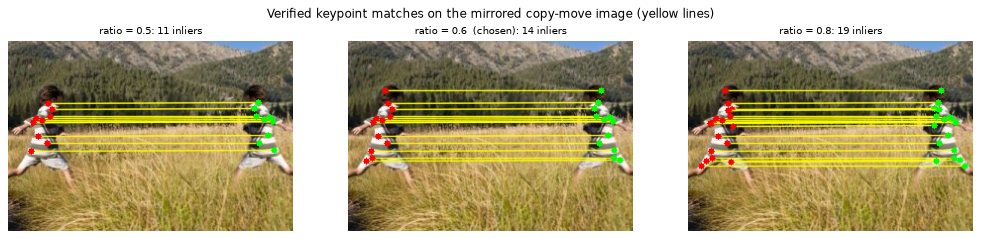

**Scores from the Phase 2 validation sweep** (`cm_keypoint`, ratio):

,image_auc,pixel_auc,score
value,,,
0.5,0.743,0.702,0.723
0.6,0.744,0.719,0.731
0.7,0.706,0.751,0.728


In [20]:
def module(name, **override):
    return build_modules([name], params={name: {**TUNED[name], **override}})[0]

test_names = ["cm1", "cm2", "cm3", "cm4", "cm_mirror", "mf1", "mf4", "mf8", "au1", "au2", "au3", "au4", "mo1", "mo4", "mo8"]
imgsR = {n: load_sample(n)[1] for n in test_names}
rat_rows = []
for ratio in (0.5, 0.6, 0.7, 0.8):
    mod = module("cm_keypoint", ratio=ratio)
    inl = {n: int(mod.match(im)["inliers"].sum()) for n, im in imgsR.items()}
    fm = [n for n in test_names if S.loc[n, "label"] == 1]; au = [n for n in test_names if S.loc[n, "label"] == 0]
    rat_rows.append({"ratio": ratio, "copy-move images matched": f"{sum(inl[n] >= 4 for n in fm)} / {len(fm)}",
                     "mean inliers (copy-move)": np.mean([inl[n] for n in fm]),
                     "authentic images with false matches": f"{sum(inl[n] >= 4 for n in au)} / {len(au)}",
                     "mean inliers (authentic)": np.mean([inl[n] for n in au])})
display(pd.DataFrame(rat_rows).set_index("ratio"))

cols = []
for ratio in (0.5, 0.6, 0.8):
    m_ = module("cm_keypoint", ratio=ratio).match(imgsR["cm_mirror"]); cols.append((ratio, m_))
show([draw_matches(imgsR["cm_mirror"], m_["src"], m_["dst"], m_["inliers"]) for _, m_ in cols],
     [f"ratio = {r}" + ("  (chosen)" if r == 0.6 else "") + f": {int(m_['inliers'].sum())} inliers" for r, m_ in cols],
     suptitle="Verified keypoint matches on the mirrored copy-move image (yellow lines)", width=4.3)
sw = pd.read_csv("supporting/sweep_records.csv"); sw["value"] = sw["value"].astype(str)
display(Markdown("**Scores from the Phase 2 validation sweep** (`cm_keypoint`, ratio):"))
display(sw[(sw.module == "cm_keypoint") & (sw.param == "ratio")][["value", "image_auc", "pixel_auc", "score"]].set_index("value").round(3))

**Explanation and decision.** The ratio is a **trade-off between detection and false matches**. A higher ratio finds more copy-moves (5 of 8 at 0.5, up to 8 of 8 at 0.8) but also gives more authentic images "consistent" matches (0 of 7 at 0.5, 4 of 7 at 0.8), mostly from genuinely repeated structure. A ratio of **0.6** was kept as the compromise: it scored best on the 1,000-image validation sweep (score 0.731, against 0.723 at 0.5, and 0.728 at 0.7 with a falling image AUC), and false matches are further limited by the other evidence and by the uncertain band, because the decision stage does not rely on matches alone. The mirrored copy is found at every ratio only because the final module also matches against the mirror image (Section 5.6).

### 6.3 ELA re-save quality, on several images

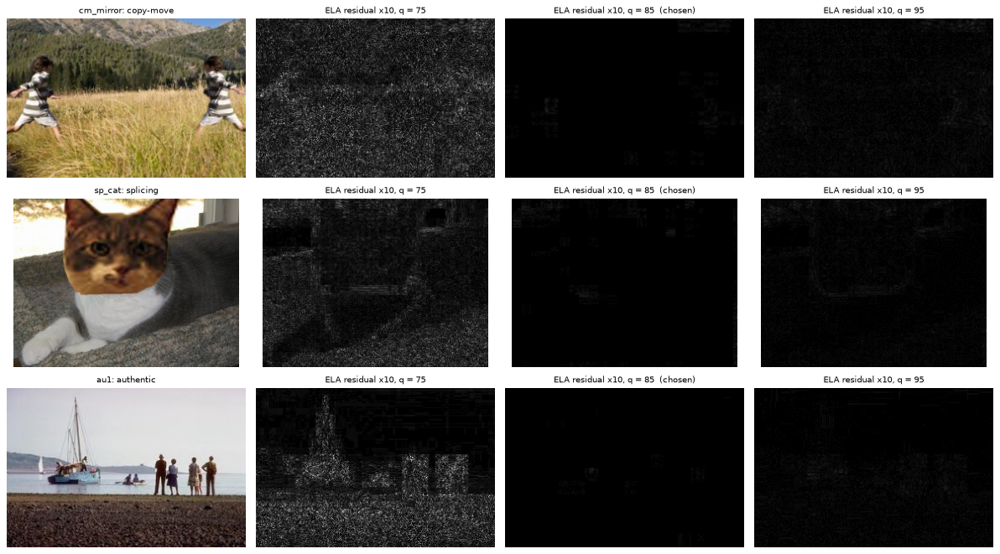

**Scores from the validation sweep** (ELA module):

,image_auc,pixel_auc,score
value,,,
75,0.684,0.548,0.616
85,0.690,0.613,0.651
90,0.701,0.551,0.626
95,0.698,0.581,0.639


In [21]:
q_names = ["cm_mirror", "sp_cat", "au1"]
fig, ax = plt.subplots(3, 4, figsize=(15, 8.4))
for r, n in enumerate(q_names):
    im = load_sample(n)[1]
    ax[r, 0].imshow(im); ax[r, 0].set_title(f"{n}: {S.loc[n,'kind']}")
    for c, q in enumerate((75, 85, 95), start=1):
        ax[r, c].imshow(np.clip(stage1_ela(im, q=q)[0] * 10, 0, 255), cmap="gray", vmin=0, vmax=255)     # same scale in every panel
        ax[r, c].set_title(f"ELA residual x10, q = {q}" + ("  (chosen)" if q == 85 else ""))
    for a in ax[r]: a.axis("off")
plt.tight_layout(h_pad=1.2); plt.show()
display(Markdown("**Scores from the validation sweep** (ELA module):"))
display(sw[(sw.module == "ela") & (sw.param == "quality")][["value", "image_auc", "pixel_auc", "score"]].set_index("value").round(3))

**Explanation and decision.** At q = 75 the re-save changes the image strongly, so error appears everywhere (bright panels) and a tampered region does not stand out; at q = 95 the re-save hardly changes the image and very little error is left. At **q = 85**, the quality at which Stage 0 saved every image, the clean background is almost error-free (nearly black panels) and only regions with a different earlier compression history remain visible. **q = 85** therefore gives the best *localisation* (pixel AUC 0.613, against 0.548 at q = 75 and 0.581 at q = 95). The proposal's q ≈ 90 was slightly better for image-level AUC but clearly worse for localisation (0.551), so we changed it.

### 6.4 The uncertain band: coverage versus accuracy
The decision stage abstains when P(tampered) lies within 0.5 ± *w*. A wider band judges fewer images but more accurately. The curve is measured on out-of-fold predictions of the development set, under protocol R.

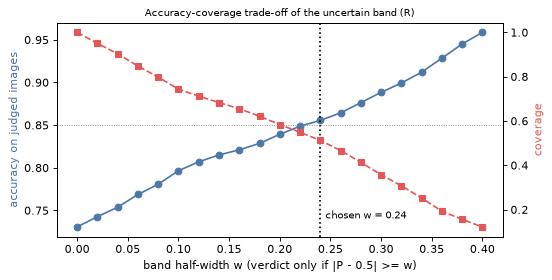

,coverage,accuracy,balanced_accuracy
half_width,,,
0.00,1.000,0.731,0.701
0.10,0.744,0.797,0.747
0.20,0.584,0.839,0.788
0.24,0.512,0.855,0.810
0.30,0.357,0.888,0.864
0.40,0.122,0.959,0.951


In [22]:
cov = pd.read_csv("supporting/phase5_coverage_R.csv")
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(cov.half_width, cov.accuracy, "o-", color="#4C78A8", label="accuracy on judged images")
ax.set_xlabel("band half-width w (verdict only if |P - 0.5| >= w)"); ax.set_ylabel("accuracy on judged images", color="#4C78A8")
ax2 = ax.twinx(); ax2.plot(cov.half_width, cov.coverage, "s--", color="#E45756", label="share of images judged"); ax2.set_ylabel("coverage", color="#E45756")
ax.axvline(0.24, color="k", ls=":"); ax.text(0.245, cov.accuracy.min() + 0.01, "chosen w = 0.24", fontsize=9)
ax.axhline(0.85, color="grey", lw=0.8, ls=":"); ax.set_title("Accuracy-coverage trade-off of the uncertain band (R)")
plt.tight_layout(); plt.show()
display(cov[np.isclose(cov.half_width.values[:, None], [0.0, 0.1, 0.2, 0.24, 0.3, 0.4]).any(axis=1)].set_index("half_width").round(3))

**Explanation and decision.** Without abstention (w = 0) the detector is right 73 % of the time and must guess on every image. At **w = 0.24**, the smallest width that reaches 85 % accuracy on the images it judges, it judges about half of them with 85.5 % accuracy. We prefer an honest "uncertain" to a coin-flip verdict, particularly because splicing evidence is often weak. The width was chosen on development predictions only; on the untouched test set the same band gave 51.8 % coverage and 0.858 accuracy (Section 7.5).

### 6.5 Localisation: how to fuse the eight evidence maps
Pixel-level quality (F1 against the ground-truth masks) on the validation images, protocol R, for each single map, for their average, and for two learned fusions (all with post-processing tuned on validation data):

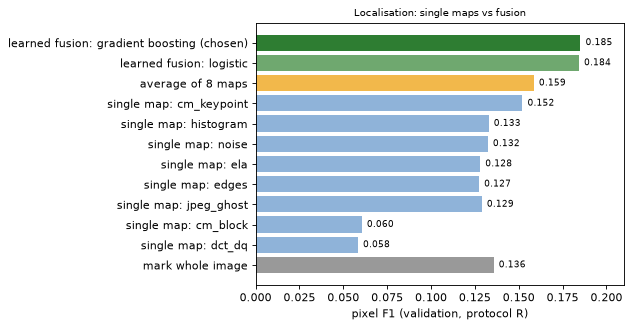

In [23]:
lm = pd.read_csv("supporting/phase6_methods_R.csv").set_index("method")
order = ["whole", "single:dct_dq", "single:cm_block", "single:jpeg_ghost", "single:edges", "single:ela", "single:noise",
         "single:histogram", "single:cm_keypoint", "mean", "logreg", "hgb"]
labels = {"whole": "mark whole image", "mean": "average of 8 maps", "logreg": "learned fusion: logistic", "hgb": "learned fusion: gradient boosting (chosen)"}
f1 = lm.loc[order, "f1"]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh([labels.get(o, o.replace("single:", "single map: ")) for o in order], f1,
        color=["#999999"] + ["#8FB3D9"] * 8 + ["#F2B84B", "#6FA86F", "#2E7D32"])
for yi, v in enumerate(f1): ax.text(v + 0.003, yi, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(0, 0.21); ax.set_xlabel("pixel F1 (validation, protocol R)"); ax.set_title("Localisation: single maps vs fusion")
plt.tight_layout(); plt.show()

**Explanation and decision.** No single map localises well: the best (SIFT copy-move, F1 0.152) is only slightly above marking the whole image (0.136), and several are worse. Averaging the maps does not help (0.159), because weak and noisy maps dilute the strong ones. A **learned fusion** that weights the maps per 8×8 cell and uses neighbouring cells as context reaches **0.185 (IoU 0.119)**; gradient boosting and logistic regression perform alike (0.185 / 0.184), and we kept gradient boosting. The fused map is also gated by the verdict: for images judged authentic the mask is removed, which cuts false regions on authentic validation images from 89 % to 42 %.

### 6.6 Final parameter selection (evidence from the validation sweeps)

In [24]:
def sweep_score(module_name, param, value):
    r = sw[(sw.module == module_name) & (sw.param == param) & (sw.value == str(value))]
    return float(r.score.iloc[0]) if len(r) else np.nan

spec = [  # module, parameter, values tested, chosen, proposal/default, reason
    ("ela", "quality", [75, 85, 90, 95], 85, 90, "best localisation (pixel AUC 0.613)"),
    ("histogram", "patch", [16, 32, 64], 16, 32, "tampered regions are small; large patches dilute the contrast"),
    ("noise", "kernel", ["laplacian", "immerkaer"], "immerkaer", "laplacian", "cancels edges and ramps, keeps noise"),
    ("jpeg_ghost", "block", [8, 16, 32], 16, 16, "best balance of image and pixel AUC"),
    ("dct_dq", "alpha", [0.001, 0.01, 0.05], 0.05, 0.05, "most reliable periodicity test (0.001 never fires)"),
    ("edges", "low", [30, 50, 80], 30, 50, "soft edges after resampling need lower thresholds (30/90)"),
    ("cm_keypoint", "detector", ["harris", "sift"], "sift", "harris", "Harris yields few, unrepeatable corners"),
    ("cm_keypoint", "ratio", [0.5, 0.6, 0.7], 0.6, 0.6, "fewer false matches on authentic images"),
]
rows = [{"module": m, "parameter": p, "values tested": ", ".join(map(str, v)), "chosen": ch, "score (chosen)": sweep_score(m, p, ch),
         "proposal / default": d, "score (proposal)": sweep_score(m, p, d), "reason": why} for m, p, v, ch, d, why in spec]
display(pd.DataFrame(rows).set_index(["module", "parameter"]).round(3))

values tested     chosen  score (chosen) proposal / default  score (proposal)                                             reason
module      parameter                                                                                                                                         
ela         quality          75, 85, 90, 95         85           0.651                 90             0.626                best localisation (pixel AUC 0.613)
histogram   patch                16, 32, 64         16           0.580                 32             0.573  tampered regions are small; large patches dilu...
noise       kernel     laplacian, immerkaer  immerkaer           0.566          laplacian             0.533               cancels edges and ramps, keeps noise
jpeg_ghost  block                 8, 16, 32         16           0.688                 16             0.688                best balance of image and pixel AUC
dct_dq      alpha         0.001, 0.01, 0.05       0.05           0.733               0.05             0.733  most reliable periodicity test (0.001 never fi...
edges       low                  30, 50, 80         30           0.592                 50             0.567  soft edges after resampling need lower thresho...
cm_keypoint detector           harris, sift       sift           0.731             harris             0.538            Harris yields few, unrepeatable corners
            ratio             0.5, 0.6, 0.7        0.6           0.731                0.6             0.731            fewer false matches on authentic images

# 7. Final Results and Evaluation

**Evaluation matches the objective.** The pipeline has two outputs, so we measure both:
- **Detection** (is the image tampered?): ROC-AUC, accuracy, precision, recall, F1 and the confusion matrix, with 95 % bootstrap confidence intervals resampled by source image.
- **Localisation** (where?): pixel-level F1 and IoU against the ground-truth masks.

We present three kinds of evidence, in order of strength:
1. **Live runs** on the sample images (7.1–7.3). Validation images were used to train the deployed models, so those results are optimistic and shown for illustration.
2. A **live run on the unseen MICC-F220 sample** (7.4).
3. The **held-out test set** of 1,892 CASIA images that were frozen before any model was trained and evaluated once (7.5). Those numbers are read from the saved evaluation, and they are the ones to rely on.

### 7.1 Original images and final outputs

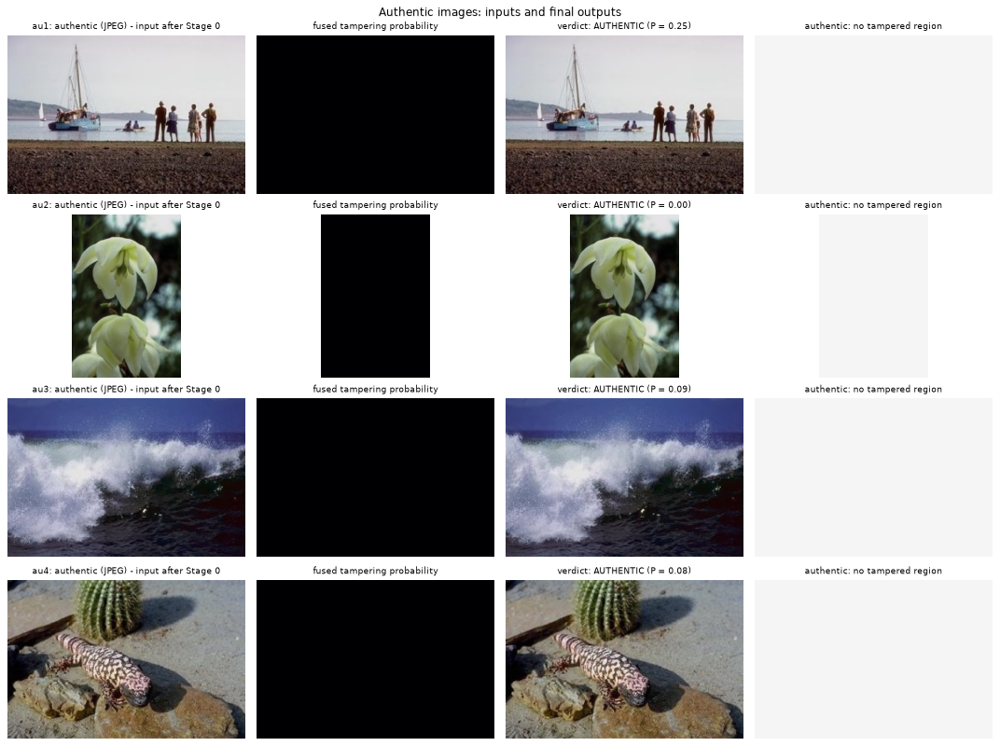

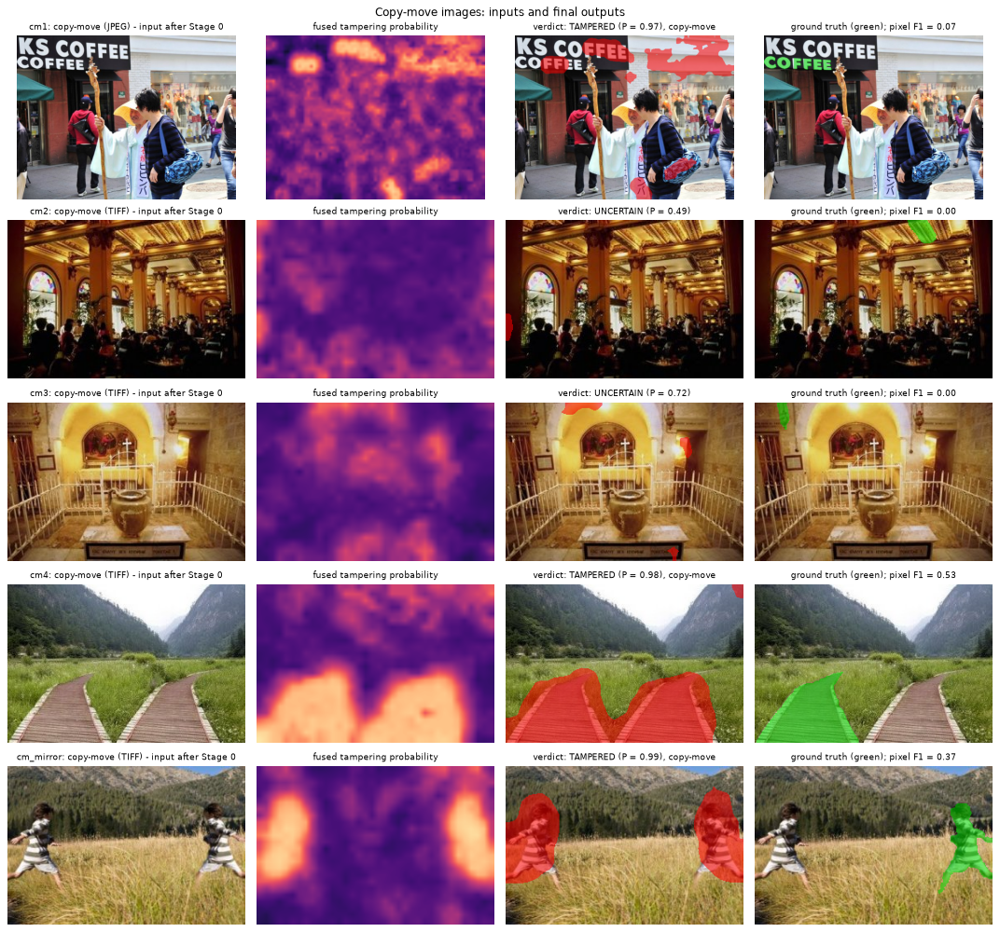

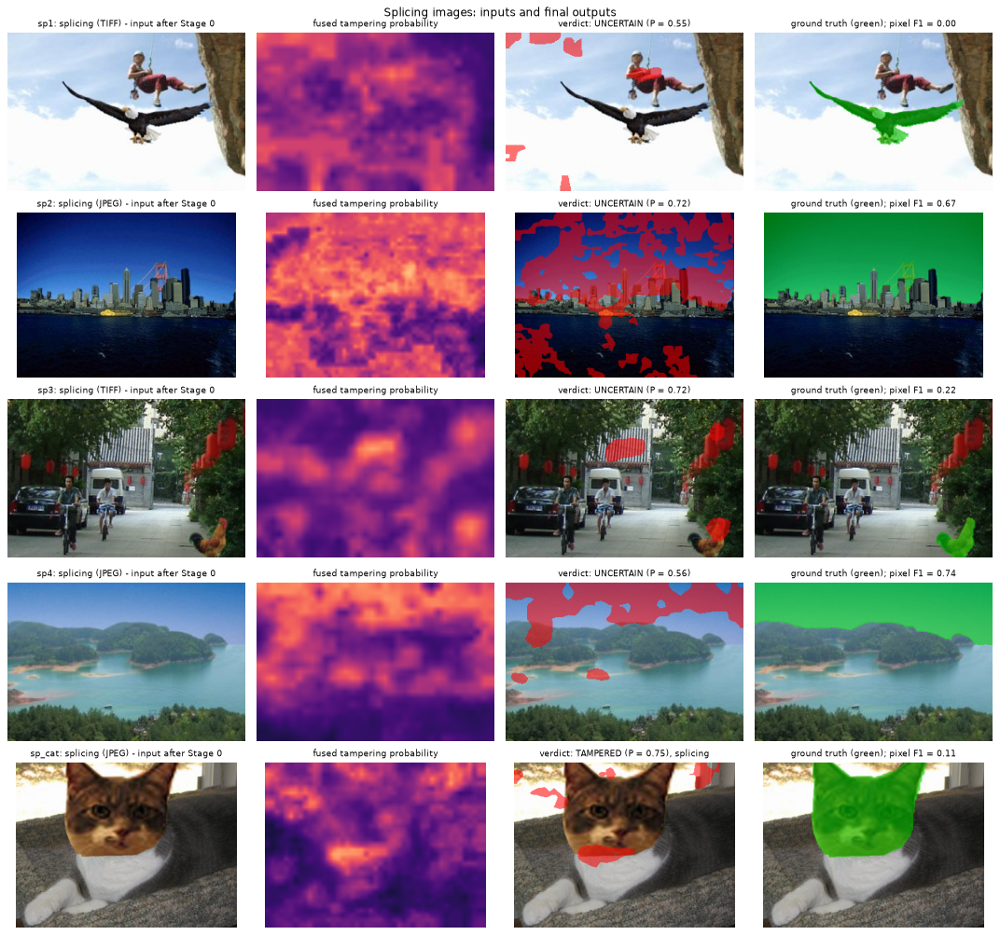

In [25]:
def gallery(names, title):
    fig, axes = plt.subplots(len(names), 4, figsize=(13.5, 2.55 * len(names)))
    axes = np.atleast_2d(axes)
    for ax, n in zip(axes, names):
        raw, img, gt = load_sample(n); res = get_result(n)
        ax[0].imshow(img); ax[0].set_title(f"{n}: {S.loc[n,'kind']} ({S.loc[n,'format']}) - input after Stage 0", fontsize=8)
        ax[1].imshow(res.fused, cmap="magma", vmin=0, vmax=1); ax[1].set_title("fused tampering probability", fontsize=8)
        ax[2].imshow(E.overlay(img, res.mask)); ax[2].set_title(f"verdict: {res.verdict.upper()} (P = {res.p:.2f})"
                                                              + (f", {res.kind}" if res.kind else ""), fontsize=8)
        if gt is not None:
            f = region_scores(res.mask, gt)["f1"]; ax[3].imshow(E.overlay(img, gt, color=(0, 220, 0)))
            ax[3].set_title(f"ground truth (green); pixel F1 = {f:.2f}", fontsize=8)
        else:
            ax[3].imshow(np.full(img.shape, 245, np.uint8)); ax[3].set_title("authentic: no tampered region", fontsize=8)
        for a in ax: a.axis("off")
    fig.suptitle(title, fontsize=11); plt.tight_layout(); plt.show()

gallery(["au1", "au2", "au3", "au4"], "Authentic images: inputs and final outputs")
gallery(["cm1", "cm2", "cm3", "cm4", "cm_mirror"], "Copy-move images: inputs and final outputs")
gallery(["sp1", "sp2", "sp3", "sp4", "sp_cat"], "Splicing images: inputs and final outputs")

In [26]:
rows = []
for n in casia:
    raw, img, gt = load_sample(n); res = get_result(n)
    rows.append({"image": n, "kind": S.loc[n, "kind"], "format": S.loc[n, "format"], "size": f"{S.loc[n,'width']}x{S.loc[n,'height']}",
                 "tampered area %": S.loc[n, "tampered_pct"], "verdict": res.verdict, "P(tampered)": res.p, "likely type": res.kind,
                 "marked area %": 100 * res.mask.mean(),
                 "pixel F1": region_scores(res.mask, gt)["f1"] if gt is not None else np.nan,
                 "IoU": region_scores(res.mask, gt)["iou"] if gt is not None else np.nan})
res_tab = pd.DataFrame(rows).set_index("image"); display(res_tab.round(3))
tp = res_tab[res_tab.kind != "authentic"]
display(Markdown(f"**Summary of the 14 sample images (in-sample, illustrative):** authentic images judged authentic: "
                 f"{int((res_tab[res_tab.kind=='authentic'].verdict=='authentic').sum())} / 4 · "
                 f"copy-move images judged tampered: {int((tp[tp.kind=='copy-move'].verdict=='tampered').sum())} / {int((tp.kind=='copy-move').sum())} · "
                 f"splicing images judged tampered: {int((tp[tp.kind=='splicing'].verdict=='tampered').sum())} / {int((tp.kind=='splicing').sum())} · "
                 f"images judged *uncertain*: {int((res_tab.verdict=='uncertain').sum())} · no authentic image was called tampered · "
                 f"mean pixel F1 on tampered images where a region was marked: {tp[tp['marked area %']>0]['pixel F1'].mean():.2f}."))

,kind,format,size,tampered area %,verdict,P(tampered),likely type,marked area %,pixel F1,IoU
image,,,,,,,,,,
au1,authentic,JPEG,384x256,0.00,authentic,0.245,NaN,0.000,NaN,NaN
au2,authentic,JPEG,256x384,0.00,authentic,0.000,NaN,0.000,NaN,NaN
au3,authentic,JPEG,384x256,0.00,authentic,0.095,NaN,0.000,NaN,NaN
au4,authentic,JPEG,384x256,0.00,authentic,0.085,NaN,0.000,NaN,NaN
cm1,copy-move,JPEG,800x600,1.32,tampered,0.969,copy-move,12.127,0.072,0.037
cm2,copy-move,TIFF,384x256,1.15,uncertain,0.486,NaN,0.434,0.000,0.000
cm3,copy-move,TIFF,384x256,0.59,uncertain,0.716,NaN,1.506,0.000,0.000
cm4,copy-move,TIFF,384x256,11.22,tampered,0.976,copy-move,31.085,0.527,0.358
sp1,splicing,TIFF,384x256,5.70,uncertain,0.548,NaN,3.950,0.000,0.000


**Summary of the 14 sample images (in-sample, illustrative):** authentic images judged authentic: 4 / 4 · copy-move images judged tampered: 3 / 5 · splicing images judged tampered: 1 / 5 · images judged *uncertain*: 6 · no authentic image was called tampered · mean pixel F1 on tampered images where a region was marked: 0.27.

**What the live runs show.**
- **Authentic images** are all judged authentic with low probability, and no region is marked.
- **Copy-move** images are found when the duplicated region has enough keypoints, and the final output marks both the original and the copy (the ground truth marks only the pasted copy, which lowers pixel F1 even for a correct detection).
- **Splicing** images are mostly judged *uncertain* rather than wrongly authentic: splices leave little compression, noise or edge evidence once the image has been re-encoded, so the detector abstains. This is the main limitation (Section 7.7).

### 7.2 Selected intermediate results
The evidence maps of the eight techniques for one copy-move and one splicing example, with the final fusion:

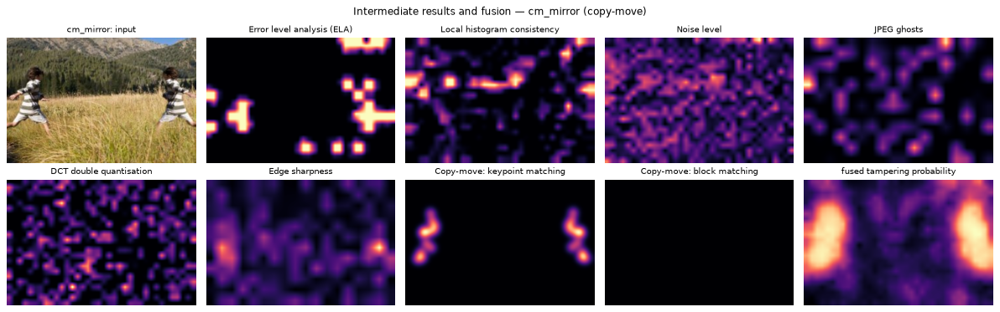

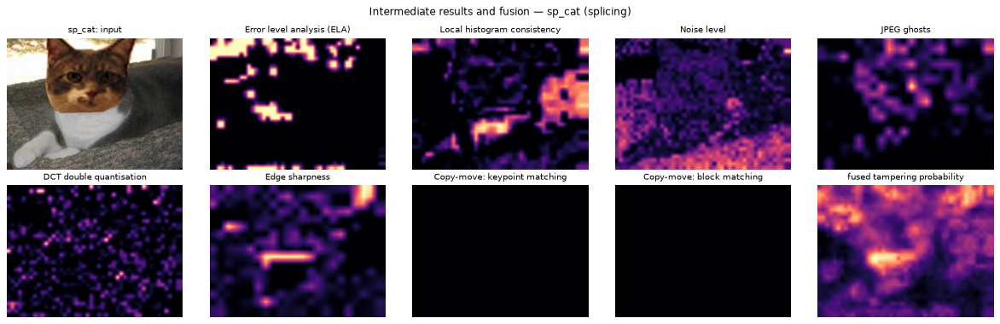

In [27]:
KEYS = ("ela", "histogram", "noise", "jpeg_ghost", "dct_dq", "edges", "cm_keypoint", "cm_block")
for n in ("cm_mirror", "sp_cat"):
    img, res = load_sample(n)[1], get_result(n)
    maps = res.maps                                  # evidence maps of the eight modules (live, or cached for these two images)
    show([img] + [maps[k] for k in KEYS] + [res.fused],
         [f"{n}: input"] + [E.MODULES[k][0] for k in KEYS] + ["fused tampering probability"],
         [None] + ["magma"] * 9, suptitle=f"Intermediate results and fusion — {n} ({S.loc[n,'kind']})", ncols=5, width=3.0, height=2.4)

**Reading the maps.** For the copy-move example the keypoint map is the clearest, with two matching clusters on the original and the copy, and the fusion keeps exactly these. For the splice, no single map isolates the pasted cat face: ELA and noise show weak responses around its edge, and the fusion produces a diffuse, low-confidence map. Compression and noise statistics of the pasted face are close to those of the photograph around it, because both come from similarly processed CASIA images.

### 7.3 Explaining one decision

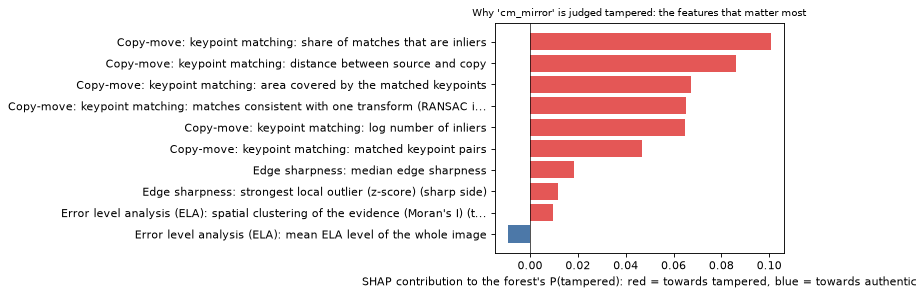

In [28]:
res = get_result("cm_mirror")
try:
    contrib = E.explain(M, res.feats, top=10) if LIVE else pd.DataFrame(CACHE["cm_mirror"]["contrib"]).head(10)
except Exception:                                    # e.g. the optional 'shap' package is not installed
    contrib = pd.DataFrame(CACHE["cm_mirror"]["contrib"]).head(10)
c = contrib.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh([d if len(d) < 80 else d[:77] + "..." for d in c.description], c.contribution,
        color=np.where(c.contribution > 0, "#E45756", "#4C78A8")); ax.axvline(0, color="k", lw=0.6)
ax.set_xlabel("SHAP contribution to the forest's P(tampered): red = towards tampered, blue = towards authentic")
ax.set_title("Why 'cm_mirror' is judged tampered: the features that matter most"); plt.tight_layout(); plt.show()

The decision is dominated by the **copy-move keypoint features**: the share of matches that are RANSAC inliers, their number, and the area they cover. The other techniques add small contributions. This is also how the model works overall: across the development set, copy-move keypoint matching and texture-normalised ELA carry most of the signal.

### 7.4 Unseen dataset: a live run on 22 MICC-F220 images
These images (11 forged scenes, one forged variant each, and 11 random originals) come from a dataset **the models have never seen**, with larger photographs and a different camera.

verdict,authentic,tampered,uncertain
true class,,,
forged,0,9,2
original,1,1,9


**AUC on these 22 images: 0.983.** With only 22 images this is a demonstration; the evaluation on all 220 images (110 forgeries from 11 scenes, 110 originals) reached AUC **0.972** under protocol R (saved result).

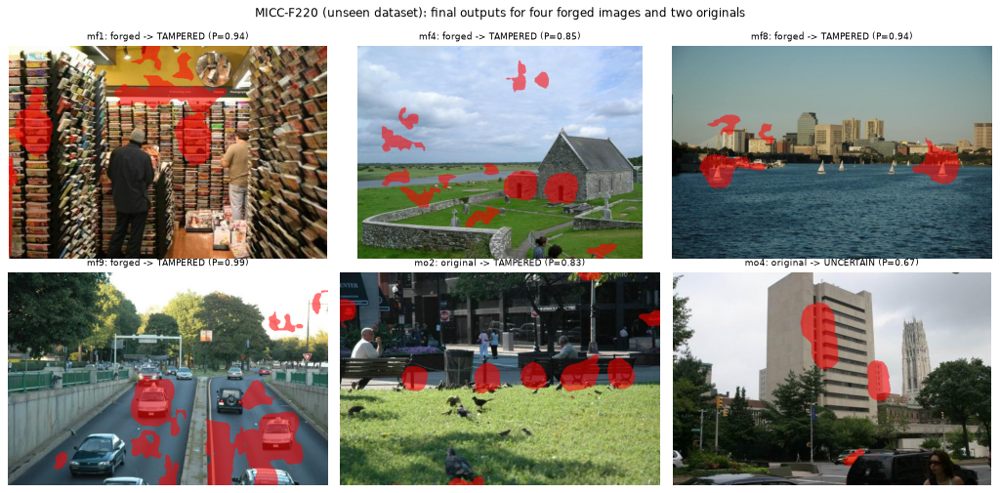

In [29]:
from sklearn.metrics import roc_auc_score
mic = [n for n in S.index if S.loc[n, "group"] == "micc"]
rows = [{"image": n, "truth": "forged" if S.loc[n, "label"] else "original", "verdict": get_result(n).verdict,
         "P(tampered)": get_result(n).p, "RANSAC inliers": int(get_result(n).feats["cm_keypoint.local_n_inliers"]),
         "marked area %": 100 * get_result(n).mask.mean()} for n in mic]
mt = pd.DataFrame(rows).set_index("image")
display(pd.crosstab(mt.truth, mt.verdict).rename_axis(index="true class", columns="verdict"))
auc22 = roc_auc_score((mt.truth == "forged").astype(int), mt["P(tampered)"])
display(Markdown(f"**AUC on these 22 images: {auc22:.3f}.** With only 22 images this is a demonstration; the evaluation on all 220 images "
                 f"(110 forgeries from 11 scenes, 110 originals) reached AUC "
                 f"**{next(r['auc'] for r in MET['micc_f220'] if r['protocol']=='R'):.3f}** under protocol R (saved result)."))

def gallery_micc(names, title):
    fig, axes = plt.subplots(2, len(names) // 2, figsize=(4.3 * (len(names) // 2), 6.4)); axes = axes.ravel()
    for ax, n in zip(axes, names):
        img = load_sample(n)[1]; r = get_result(n)
        ax.imshow(E.overlay(img, r.mask)); ax.axis("off")
        ax.set_title(f"{n}: {'forged' if S.loc[n,'label'] else 'original'} -> {r.verdict.upper()} (P={r.p:.2f})", fontsize=8.5)
    fig.suptitle(title, fontsize=11); plt.tight_layout(); plt.show()

fa = mt[(mt.truth == "original") & (mt.verdict == "tampered")].index.tolist()
shown = ["mf1", "mf4", "mf8", "mf9"] + (fa[:1] or ["mo1"]) + ["mo4"]
gallery_micc(shown[:6], "MICC-F220 (unseen dataset): final outputs for four forged images and two originals")

**Reading the result.** The pipeline finds the forgeries in this unseen dataset and marks the duplicated regions, which shows the techniques transfer beyond CASIA. It also shows the typical **unwanted artifact**: an *original* photograph can be flagged when it contains genuinely repeated structure (rows of similar objects, shelves, windows). Keypoint matching cannot tell a duplicated region from a naturally repeated one. Most originals are judged *uncertain* rather than wrongly tampered, because of the abstention band.

### 7.5 Held-out test set (1,892 CASIA images, evaluated once)
These numbers come from the saved one-time evaluation of the frozen pipeline. The test split was fixed by hash before any model was trained and was not used for any tuning.

In [30]:
tc = pd.DataFrame(MET["test_classification"])
a = tc[(tc.model == "rf") & tc.feature_set.isin(["shortcuts", "forensic_all", "forensic+shortcuts"])].copy()
a["AUC [95 % CI]"] = [f"{v:.3f} [{l:.3f}, {h:.3f}]" for v, l, h in zip(a.auc, a.auc_ci_low, a.auc_ci_high)]
display(Markdown("**Detection: test AUC by feature set and protocol** (random forest):"))
display(a.pivot_table(index="feature_set", columns="protocol", values="AUC [95 % CI]", aggfunc="first")
         .rename(index={"shortcuts": "shortcut features only", "forensic_all": "our 8 techniques (final)",
                        "forensic+shortcuts": "techniques + shortcuts"})[["R", "B", "A"]])
av = pd.DataFrame(MET["test_added_value"]); r_ = av[(av.protocol == "R") & (av.model == "rf") & (av.comparison == "forensic+shortcuts - shortcuts")].iloc[0]
print(f"Added value of the techniques over the shortcuts (R): +{r_.delta_auc:.3f} (95 % CI {r_.ci_low:.3f} to {r_.ci_high:.3f})")

thr = tc[(tc.feature_set == "forensic_all") & (tc.model == "rf") & tc.protocol.isin(["R", "B"])].set_index("protocol")
display(Markdown("**At threshold 0.5** (uncalibrated forest):"))
display(thr[["accuracy", "precision", "recall", "f1", "balanced_accuracy"]].round(3))

**Detection: test AUC by feature set and protocol** (random forest):

protocol,R,B,A
feature_set,,,
techniques + shortcuts,"0.815 [0.789, 0.840]","0.936 [0.925, 0.947]","1.000 [0.999, 1.000]"
our 8 techniques (final),"0.805 [0.779, 0.831]","0.920 [0.905, 0.934]","0.981 [0.975, 0.986]"
shortcut features only,"0.712 [0.682, 0.746]","0.886 [0.870, 0.903]","1.000 [0.999, 1.000]"


Added value of the techniques over the shortcuts (R): +0.103 (95 % CI 0.076 to 0.129)


**At threshold 0.5** (uncalibrated forest):

,accuracy,precision,recall,f1,balanced_accuracy
protocol,,,,,
R,0.75,0.756,0.567,0.648,0.721
B,0.85,0.813,0.819,0.816,0.845


In [31]:
dep = MET["test_deployed"]["R"]
cm_ = pd.DataFrame(dep["confusion_matrix"]).T[["authentic", "tampered", "uncertain"]]
display(Markdown(f"**Deployed detector (calibrated, uncertain band 0.5 ± {dep['band']}), protocol R:** it judged **{100*dep['coverage']:.1f} %** of the 1,892 test images, "
                 f"with accuracy **{dep['accuracy_judged']:.3f}** on those. Verdicts versus truth:"))
display(cm_.rename_axis(index="true class", columns="verdict"))
fp, tp_ = cm_.loc["authentic", "tampered"], cm_.loc["tampered", "tampered"]
print(f"A 'tampered' verdict was right {100*tp_/(tp_+fp):.0f} % of the time ({tp_} of {tp_+fp}); "
      f"an 'authentic' verdict {100*cm_.loc['authentic','authentic']/(cm_.loc['authentic','authentic']+cm_.loc['tampered','authentic']):.0f} % of the time.")

loc = MET["test_localisation"]
lt = pd.DataFrame({P: {"pixel F1": v["f1"], "IoU": v["iou"], "MCC": v["mcc"], "pixel AUC": v["pixel_auc"],
                       **{f"F1, region {k}": x for k, x in v["f1_by_area"].items()},
                       **{f"F1, {k}": x for k, x in v["f1_by_type"].items()}} for P, v in loc.items()})
display(Markdown("**Localisation on the 766 tampered test images with a valid mask** (deployed localiser):"))
display(lt.round(3))

**Deployed detector (calibrated, uncertain band 0.5 ± 0.24), protocol R:** it judged **51.8 %** of the 1,892 test images, with accuracy **0.858** on those. Verdicts versus truth:

verdict,authentic,tampered,uncertain
true class,,,
authentic,619,13,491
tampered,126,222,421


A 'tampered' verdict was right 94 % of the time (222 of 235); an 'authentic' verdict 83 % of the time.


**Localisation on the 766 tampered test images with a valid mask** (deployed localiser):

,R,B
pixel F1,0.198,0.308
IoU,0.128,0.210
MCC,0.163,0.296
pixel AUC,0.714,0.829
"F1, region 1-5%",0.148,0.295
"F1, region <1%",0.040,0.123
"F1, region >5%",0.333,0.413
"F1, copy-move",0.236,0.354
"F1, splicing",0.129,0.226


**Test ROC (protocol R)** and **error analysis**: saved figures of the one-time evaluation. The error-analysis figure shows the most confident detections, missed forgeries and false alarms of the held-out test set:

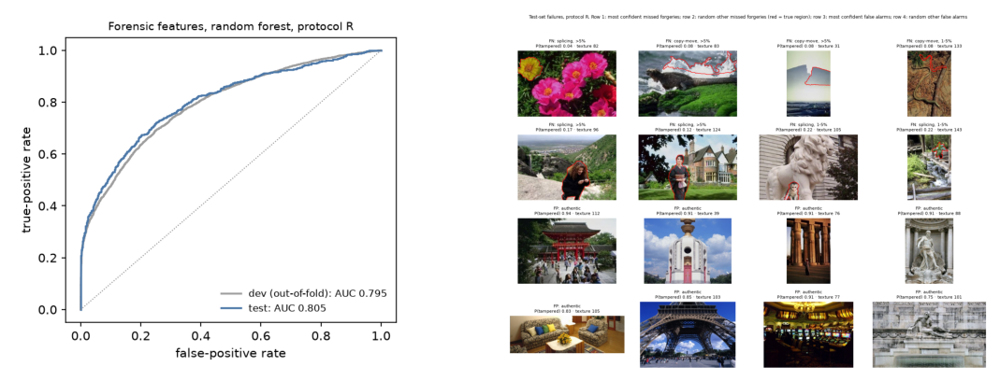

In [32]:
from IPython.display import Image as IPImage
display(Markdown("**Test ROC (protocol R)** and **error analysis**: saved figures of the one-time evaluation. The error-analysis figure shows the most confident detections, "
                 "missed forgeries and false alarms of the held-out test set:"))
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1, 1.35]})
ax[0].imshow(plt.imread("supporting/fig_roc_test_R.png")); ax[1].imshow(plt.imread("supporting/fig_error_analysis.png"))
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### 7.6 Robustness and comparison with a deep-learning baseline
The frozen pipeline was re-run on the test images after degrading them *before* the protocol, and compared with an ELA + ResNet-18 convolutional network trained under the same protocols (optional in this course).

In [33]:
rb = pd.DataFrame(MET["robustness"]); rb = rb[rb.protocol == "R"].set_index("condition")[["auc", "loc_f1"]]
rb.columns = ["image AUC (R)", "pixel F1 (R)"]
display(Markdown("**Robustness of the deployed pipeline** (test images, protocol R):")); display(rb.round(3))
cnn_rows = [{"protocol": P, "ELA-CNN AUC": r["cnn_auc"]["auc"], "classical pipeline AUC": r["classical_auc"]["auc"],
             "MICC-F220, CNN": (r.get("micc_f220") or {}).get("auc")} for P, r in MET["cnn"].items()]
display(Markdown("**Deep-learning baseline** (test AUC):")); display(pd.DataFrame(cnn_rows).set_index("protocol").round(3))

**Robustness of the deployed pipeline** (test images, protocol R):

,image AUC (R),pixel F1 (R)
condition,,
clean,0.805,0.198
JPEG Q95,0.792,0.198
JPEG Q85,0.793,0.193
JPEG Q75,0.799,0.193
JPEG Q65,0.779,0.194
JPEG Q50,0.781,0.191
resize x0.9,0.792,0.193
resize x0.75,0.768,0.174
resize x0.5,0.693,0.126


**Deep-learning baseline** (test AUC):

,ELA-CNN AUC,classical pipeline AUC,"MICC-F220, CNN"
protocol,,,
R,0.770,0.805,0.529
B,0.811,0.920,0.454
A,0.994,0.981,NaN


**Reading the evaluation.**
- **Detection works above what shortcuts achieve.** Under the strict protocol the eight techniques reach **AUC 0.805** (95 % CI 0.779–0.831) against **0.712** for the shortcut features. Added on top of the shortcuts they gain **+0.103**. The test result matches the development estimate (0.795), so the pipeline did not over-fit the development data.
- **Calibrated abstention works.** It judges 52 % of images with 86 % accuracy, and a "tampered" verdict is right 94 % of the time.
- **Localisation is moderate.** Pixel F1 is **0.198** under R (0.333 for regions above 5 % of the image, 0.04 below 1 %), because CASIA's tampered regions are small and the maps are coarse.
- **The pipeline is robust to re-saving and noise** (AUC ≥ 0.78 down to JPEG quality 50), and a social-media-style upload costs about 0.04 AUC.
- **The deep-learning baseline only looks strong on the leaking files.** It reaches 0.994 under protocol A, where the shortcuts alone reach 1.000. Under R it trails the classical pipeline, and on MICC-F220 its AUC is consistent with chance.

### 7.7 Strengths, limitations and unwanted artifacts

| | |
|---|---|
| **Strengths** | Interpretable: every verdict comes with eight evidence maps and a feature attribution. Copy-move, including rotated, scaled and **mirrored** copies, is found reliably, and the pipeline transfers to an unseen dataset (AUC 0.972). It abstains instead of guessing. It is robust to re-compression and noise, and every number is measured against the shortcut baselines. |
| **Limitations** | **Splicing is the weakest case.** After protocol R, splices from similarly processed photographs leave little compression, noise or edge evidence (splicing-vs-authentic test AUC about 0.68). **Localisation is coarse and mediocre** for small regions (8×8 cells). **Strong downscaling** (×0.5) costs about 0.11 AUC. Under R, DCT double quantisation is near chance, because resampling destroys the 8×8 grid it relies on. |
| **Unwanted artifacts** | **False alarms on repeated structure** (columns, shelves, windows, patterns): all 13 confident false alarms in the test set had RANSAC-verified copy-move matches. **Both copies are marked** in a copy-move, although the ground truth marks only the pasted one, which lowers pixel F1. ELA and the noise maps also respond to **texture and edges**, which is why they are normalised by texture and edge-masked. |

# 8. Challenges, Improvements, and Conclusion

### Challenges encountered
- **The dataset leaks its labels.** File format and JPEG tables alone predict the class (0.990 balanced accuracy). We had to redesign the evaluation (protocol R, shortcut baselines, a leakage-safe split that keeps duplicates together), which lowered every headline number but made them honest.
- **Data quality:** 142 misnamed masks, 19 unusable masks and 99 inconsistent type labels had to be repaired; near-duplicate images had to be kept within one split.
- **Bugs found and fixed along the way:**
  - the DCT periodicity test had 16–48 % false positives on wide histograms, fixed with a permutation test (0–3 %);
  - the noise module treated flat patches as outliers;
  - the copy-move matcher missed mirrored copies and split a copy into two opposite transforms.
- **Tiny, low-detail images** (384×256) leave few keypoints and blocks, and the tampered regions are tiny (median 3 %).
- **Evaluation discipline:** keeping a test set untouched while tuning, and documenting each use of it.

### Modifications since Phase 2
The first three rows changed the pipeline and its models, and all of that was done **before** the pipeline was frozen and the test set was used (Section 4.1). The last two rows came after the freeze and only *evaluate or explain* the frozen pipeline; they do not change it.

| Phase 2 | Phase 3 |
|---|---|
| Eight modules with per-technique parameter sweeps | **All modules re-tuned** after the bug fixes; protocol R made the main setting |
| Features and a first classifier comparison | **Calibrated random forest + uncertain band**; model chosen by grouped nested cross-validation |
| Evidence maps only | **Learned fusion of the maps** into a suspected-region mask, **gated** by the verdict |
| Development-set numbers | **One-time held-out test evaluation**, robustness tests and an **unseen dataset (MICC-F220)** |
| — | Per-image **explanations (SHAP)**, an interactive **Streamlit interface**, and an optional **CNN baseline** |

### Techniques and settings that did not work as expected
- **Harris corners** (proposal) for copy-move: few, unstable corners (image AUC 0.564 vs 0.744 for SIFT); replaced.
- **3×3 Laplacian** noise filter: responds to edges; replaced by Immerkær's kernel with edge masking.
- **32×32 histogram patches** and **Canny 50/150**: weaker than 16×16 and 30/90 on these small images.
- **DCT double quantisation under protocol R:** near chance (alone AUC 0.519), because resampling removes the JPEG grid. **Histogram χ²** and **DCT-block copy-move** add little over the other techniques.
- **Global statistics** (file format, size, naive ELA level) look powerful but mostly measure compression history, not tampering.
- **A deep ELA-CNN** looks excellent on the leaking files and does not generalise.

### Key findings and lessons learned
1. A benchmark can be solved without looking at the image; **check for shortcuts** and compare every method with what they achieve alone.
2. Under leak control, **classical techniques still carry real evidence**: test AUC 0.805, +0.103 over the shortcuts, and 0.972 on an unseen copy-move dataset.
3. **Copy-move is found far more reliably than splicing**; combining several weak cues (ELA, noise, edges) matters mainly for splicing.
4. **Abstaining is better than guessing:** the calibrated *uncertain* band gives 86 % accuracy on the images it judges.
5. More techniques are not always better: only some of the eight carry most of the signal, and parameters tuned on small images must be validated on images the tuning never saw.

### Possible future improvements (not part of the submitted pipeline)
These are ideas for future work. None of them was applied: the pipeline submitted here is the frozen version of Section 4.1.
- Cues aimed at **same-history splices**, such as sensor-noise (PRNU) consistency.
- **Suppress copy-move false alarms** on genuinely repeated structure, for example by testing whether the matched regions' surroundings also match.
- **Finer localisation** for regions below 1 % of the image (denser cells, boundary refinement).
- A **cross-dataset splicing** benchmark, and training learned detectors under the same leak controls.

**Conclusion.** The final (frozen) pipeline of Section 4.1 meets the project objective: it decides whether an image is tampered and where, using eight interpretable classical techniques from all five course categories, and its measured performance on a frozen test set and on an unseen dataset shows genuine tampering evidence beyond dataset shortcuts. Its main weaknesses, splicing and small-region localisation, are identified and explained.

---
**References.** Dong, Wang & Tan, *CASIA Image Tampering Detection Evaluation Database*, ChinaSIP 2013 · Amerini et al., *A SIFT-based forensic method for copy-move attack detection and transformation recovery*, IEEE TIFS 2011 · Farid, *Exposing digital forgeries from JPEG ghosts*, IEEE TIFS 2009 · Lin et al., *Fast, automatic and fine-grained tampered JPEG image detection via DCT coefficient analysis*, Pattern Recognition 2009 · Krawetz, *A Picture's Worth*, Black Hat 2007 (error level analysis) · Immerkær, *Fast noise variance estimation*, CVIU 1996 · Canny, *A computational approach to edge detection*, IEEE TPAMI 1986 · Lowe, *Distinctive image features from scale-invariant keypoints*, IJCV 2004 · Fischler & Bolles, *Random sample consensus*, CACM 1981 · Breiman, *Random forests*, Machine Learning 2001 · Lundberg & Lee, *A unified approach to interpreting model predictions*, NeurIPS 2017. Full list: the final project report.